## NBA Play by Play EDA
**- Owner:** Alex

**- Status:** Exploration only

**- Last Updated:** 10/23/26

### Question

**How does shot selection differ across NBA teams, and which shot zones contribute the most points per attempt?**

### Scope 
**2025-26 regular season stats, all 30 teams. Free throws and possesssions are outside the scope.**


### Setup and Scope

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

def repo_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "raw" / "pbp_stats").is_dir():
            return candidate
    raise FileNotFoundError("Could not find data/raw/pbp_stats. Open this notebook from the repo.")

ROOT = repo_root()
PBP = ROOT / "data" / "raw" / "pbp_stats"

s22 = pd.read_parquet(PBP / 's22_pbp.parquet')
s22['season'] = '2021-22'
s23 = pd.read_parquet(PBP / 's23_pbp.parquet')
s23['season'] = '2022-23'
s24 = pd.read_parquet(PBP / 's24_pbp.parquet')
s24['season'] = '2023-24'
s25 = pd.read_parquet(PBP / 's25_pbp.parquet')
s25['season'] = '2024-25'
s26 = pd.read_parquet(PBP / 's26_pbp.parquet')
s26['season'] = '2025-26'

pbp = pd.concat([s22, s23, s24, s25, s26])
print(f"Columns: {pbp.columns.tolist()}")
print(f"Rows: {pbp.shape[0]:,}")
pbp.head(5)


Columns: ['gameId', 'actionNumber', 'clock', 'period', 'teamId', 'teamTricode', 'personId', 'playerName', 'playerNameI', 'xLegacy', 'yLegacy', 'shotDistance', 'shotResult', 'isFieldGoal', 'scoreHome', 'scoreAway', 'pointsTotal', 'location', 'description', 'actionType', 'subType', 'videoAvailable', 'shotValue', 'actionId', 'season']
Rows: 3,227,917


,gameId,actionNumber,clock,period,teamId,teamTricode,personId,playerName,playerNameI,xLegacy,...,scoreAway,pointsTotal,location,description,actionType,subType,videoAvailable,shotValue,actionId,season
0,0022100002,2,PT12M00.00S,1,0,NaN,0,NaN,NaN,0,...,0.0,0,NaN,Start of 1st Period (10:11 PM EST),period,start,0,0,1,2021-22
1,0022100002,4,PT12M00.00S,1,1610612747,LAL,201599,Jordan,D. Jordan,0,...,NaN,0,h,Jump Ball Jordan vs. Looney: Tip to Davis,Jump Ball,NaN,1,0,2,2021-22
2,0022100002,7,PT11M53.00S,1,1610612747,LAL,201599,Jordan,D. Jordan,5,...,0.0,2,h,Jordan 2' Alley Oop Layup (2 PTS) (James 1 AST),Made Shot,Alley Oop Layup shot,1,2,3,2021-22
3,0022100002,9,PT11M37.00S,1,1610612744,GSW,1626172,Looney,K. Looney,-12,...,2.0,4,v,Looney 2' Cutting Layup Shot (2 PTS) (Curry 1 ...,Made Shot,Cutting Layup Shot,1,2,4,2021-22
4,0022100002,11,PT11M24.00S,1,1610612747,LAL,2544,James,L. James,0,...,NaN,0,h,James Lost Ball Turnover (P1.T1),Turnover,Lost Ball,1,0,5,2021-22


## 2. Select the scoped actions

The setup cell loads every stored season into `pbp`. The cells below keep that frame and apply the scope at the top of the notebook: the 2025-26 regular season and every team in the frame.

Regular-season games are rows whose `gameId` begins with `002`. Change `SEASONS` or `TEAM_CODES` in the next cell to narrow the extract. Set `TEAM_CODES` to a tuple such as `("LAL", "GSW")` for a smaller comparison, or `SEASONS` to `None` to use every season already loaded in `pbp`.

Free throws and heaves remain in the action table for the audit. Field-goal attempts are selected in the next section. Possessions stay outside the scope.

In [20]:
import json
import sqlite3
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# Defaults match the scope at the top of the notebook.
INPUT_PATH = None
DATAFRAME_NAME = "pbp"
TEAM_CODES = None
SEASONS = ("2025-26",)
REGULAR_SEASON_ONLY = True
PLOT_SEASON = None

def repo_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "raw" / "pbp_stats").is_dir():
            return candidate
    raise FileNotFoundError("Could not find data/raw/pbp_stats. Open this notebook from the repo.")

ROOT = repo_root()
OUTPUT_DIR = ROOT / "data" / "shot_selection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TEAM_COLORS = ["#2563eb", "#d97706", "#059669", "#9333ea"]
REQUIRED_COLUMNS = [
    "gameId",
    "actionNumber",
    "teamId",
    "teamTricode",
    "personId",
    "actionType",
    "shotValue",
    "season",
]
OPTIONAL_COLUMNS = [
    "shotResult",
    "isFieldGoal",
    "shotDistance",
    "xLegacy",
    "yLegacy",
    "description",
    "pointsTotal",
    "actionId",
]
INPUT_COLUMNS = REQUIRED_COLUMNS + OPTIONAL_COLUMNS


def scope_events(frame):
    missing = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
    if missing:
        raise ValueError(f"Missing input columns: {missing}")

    # The setup cell concatenates season files with pd.concat, so index labels
    # repeat. Select by row position so those labels cannot realign the mask.
    game_ids = (
        frame["gameId"]
        .astype("string")
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(10)
    )
    mask = np.ones(len(frame), dtype=bool)
    if REGULAR_SEASON_ONLY:
        mask &= game_ids.str.startswith("002", na=False).to_numpy()
    if TEAM_CODES is not None:
        mask &= frame["teamTricode"].isin(TEAM_CODES).fillna(False).to_numpy()
    if SEASONS is not None:
        mask &= frame["season"].isin(SEASONS).fillna(False).to_numpy()

    columns = [column for column in INPUT_COLUMNS if column in frame.columns]
    positions = np.flatnonzero(mask)
    selected = frame.iloc[positions].loc[:, columns].copy()
    selected["gameId"] = game_ids.iloc[positions].astype("string").to_numpy()
    return selected.reset_index(drop=True)


if INPUT_PATH is None:
    source_frame = globals().get(DATAFRAME_NAME)
    if not isinstance(source_frame, pd.DataFrame):
        raise ValueError(
            "Run the setup cell so pbp exists, or set INPUT_PATH to a CSV or Parquet file."
        )
    input_rows = len(source_frame)
    events = scope_events(source_frame)
    input_source = f"In-memory DataFrame: {DATAFRAME_NAME}"
else:
    input_path = Path(INPUT_PATH)
    input_source = str(input_path.resolve())
    if input_path.suffix.lower() == ".csv":
        parts, input_rows = [], 0
        for chunk in pd.read_csv(
            input_path,
            usecols=lambda column: column in INPUT_COLUMNS,
            dtype={"gameId": "string"},
            chunksize=250_000,
            low_memory=False,
        ):
            input_rows += len(chunk)
            selected = scope_events(chunk)
            if not selected.empty:
                parts.append(selected)
        if not parts:
            raise ValueError("No actions match the configured scope.")
        events = pd.concat(parts, ignore_index=True)
    elif input_path.suffix.lower() in {".parquet", ".pq"}:
        import pyarrow.parquet as parquet

        available = parquet.ParquetFile(input_path).schema_arrow.names
        columns = [column for column in INPUT_COLUMNS if column in available]
        source_frame = pd.read_parquet(input_path, columns=columns)
        input_rows = len(source_frame)
        events = scope_events(source_frame)
        del source_frame
    else:
        raise ValueError("INPUT_PATH must point to a CSV or Parquet file.")

if events.empty:
    raise ValueError("No actions match the configured scope.")
events = events.reset_index(drop=True)
metadata = {
    "input": input_source,
    "input_rows": int(input_rows),
    "selected_action_rows": len(events),
    "team_codes": None if TEAM_CODES is None else list(TEAM_CODES),
    "seasons": None if SEASONS is None else list(SEASONS),
    "regular_season_only": REGULAR_SEASON_ONLY,
    "plot_season": PLOT_SEASON,
    "analysis_run_utc": datetime.now(timezone.utc).isoformat(),
    "collection_note": (
        "pbp is built in the setup cell from data/raw/pbp_stats season parquet files. "
        "Record the nba_api endpoint and retrieval time in that cell before sharing."
    ),
}
(OUTPUT_DIR / "input_metadata.json").write_text(json.dumps(metadata, indent=2))
print(
    f"Input actions: {input_rows:,}. "
    f"In scope: {len(events):,} actions "
    f"({input_rows - len(events):,} excluded by season, team, or regular-season filters)."
)
display(events[["gameId", "teamTricode", "actionType", "shotValue", "season"]].head())

Input actions: 3,227,917. In scope: 621,881 actions (2,606,036 excluded by season, team, or regular-season filters).


,gameId,teamTricode,actionType,shotValue,season
0,0022500085,,period,0,2025-26
1,0022500085,MEM,Jump Ball,0,2025-26
2,0022500085,MEM,Turnover,0,2025-26
3,0022500085,NOP,,0,2025-26
4,0022500085,NOP,Made Shot,2,2025-26


## 3. Extract shots and validate the attempt rows

Candidate shots are normalized `actionType` values `made shot`, `missed shot`, `2pt`, or `3pt`, with `shotValue` of 2 or 3. The outcome comes from the made or missed action label. `shotResult` fills in when the action label is `2pt` or `3pt`. The cell stops if those sources disagree.

`isFieldGoal` is cross-tabulated so the flag can be audited. The shot filter uses `actionType`. Heave rows in this feed are team markers with `shotValue` 0; the cell counts them and leaves them out of the attempt set.

The shot key is `(gameId, actionNumber)` on shot rows. The same action number can appear on a non-shot row, such as a turnover and the steal tied to it.

Points on an attempt are `made × shotValue`. `pointsTotal`, `scoreHome`, and `scoreAway` are running scores.

In [21]:
action_types = events["actionType"].astype("string").str.strip().str.lower()
heave_rows = int(action_types.eq("heave").sum())
free_throw_rows = int(action_types.eq("free throw").sum())
print(f"Heave rows left out of field-goal attempts: {heave_rows:,}")
print(f"Free-throw rows left out of field-goal attempts: {free_throw_rows:,}")

shot_actions = {"made shot", "missed shot", "2pt", "3pt"}
if "isFieldGoal" in events:
    flag_audit = pd.crosstab(
        action_types.fillna("missing action type"),
        events["isFieldGoal"].astype("string").fillna("missing flag"),
    )
    display(flag_audit)

shots = events.loc[action_types.isin(shot_actions)].copy().reset_index(drop=True)
if shots.empty:
    raise ValueError("No supported shot actions found. Inspect actionType values.")
shot_types = shots["actionType"].astype("string").str.strip().str.lower()
action_outcome = shot_types.map({"made shot": 1, "missed shot": 0})
result_outcome = pd.Series(np.nan, index=shots.index)
if "shotResult" in shots:
    result_outcome = (
        shots["shotResult"]
        .astype("string")
        .str.strip()
        .str.lower()
        .map(
            {
                "made": 1,
                "missed": 0,
                "made shot": 1,
                "missed shot": 0,
            }
        )
    )
contradictions = (
    action_outcome.notna() & result_outcome.notna() & action_outcome.ne(result_outcome)
)
shots["made"] = action_outcome.combine_first(result_outcome)
shots["shot_value"] = pd.to_numeric(shots["shotValue"], errors="coerce")
for column in ["teamId", "personId", "actionNumber"]:
    shots[column] = pd.to_numeric(shots[column], errors="coerce")

duplicate_shots = shots.duplicated(["gameId", "actionNumber"], keep=False)
ids_valid = (
    shots[["teamId", "personId", "actionNumber"]]
    .apply(lambda column: column.notna() & column.gt(0) & column.mod(1).eq(0))
    .all()
    .all()
)
checks = {
    "Unique shot-action keys": not duplicate_shots.any(),
    "Game IDs have ten digits": shots["gameId"].str.fullmatch(r"\d{10}", na=False).all(),
    "Team, player, and action IDs are positive integers": ids_valid,
    "Team tricodes are present": shots["teamTricode"].fillna("").str.strip().ne("").all(),
    "Season labels are valid": shots["season"]
    .astype("string")
    .str.fullmatch(r"\d{4}-\d{2}", na=False)
    .all(),
    "Shot values are 2 or 3": shots["shot_value"].isin([2, 3]).all(),
    "Shot outcomes are resolved": shots["made"].isin([0, 1]).all(),
    "Outcome sources agree": not contradictions.any(),
    "2pt and 3pt labels agree with shot value": (
        (~shot_types.eq("2pt") | shots["shot_value"].eq(2))
        & (~shot_types.eq("3pt") | shots["shot_value"].eq(3))
    ).all(),
}
display(pd.DataFrame({"check": checks.keys(), "passed": checks.values()}))
if duplicate_shots.any():
    display(shots.loc[duplicate_shots].head(10))
failed = [name for name, passed in checks.items() if not passed]
if failed:
    raise ValueError(f"Resolve failed shot checks before calculating efficiency: {failed}")

shots["made"] = shots["made"].astype(int)
shots["shot_value"] = shots["shot_value"].astype(int)
shots["points"] = shots["made"] * shots["shot_value"]
shots["three_made"] = (shots["made"].eq(1) & shots["shot_value"].eq(3)).astype(int)
if not (shots["points"] == shots["made"] * shots["shot_value"]).all():
    raise AssertionError("Points must equal made times shot value.")
coverage = shots.groupby(["season", "teamTricode"], as_index=False).agg(
    games=("gameId", "nunique"),
    attempts=("gameId", "size"),
).sort_values(["season", "teamTricode"])
display(coverage)
print(
    f"Teams: {shots['teamTricode'].nunique()}. "
    f"Games per team: {int(coverage['games'].min())}–{int(coverage['games'].max())}. "
    "A partial season is visible here before any efficiency comparison."
)

Heave rows left out of field-goal attempts: 1,093
Free-throw rows left out of field-goal attempts: 57,768


isFieldGoal,0,1
actionType,,
,32619,0
ejection,67,0
foul,50050,0
free throw,57768,0
heave,1093,0
instant replay,3177,0
jump ball,2282,0
made shot,0,103227
missed shot,0,115932


,check,passed
0,Unique shot-action keys,True
1,Game IDs have ten digits,True
2,"Team, player, and action IDs are positive inte...",True
3,Team tricodes are present,True
4,Season labels are valid,True
5,Shot values are 2 or 3,True
6,Shot outcomes are resolved,True
7,Outcome sources agree,True
8,2pt and 3pt labels agree with shot value,True


,season,teamTricode,games,attempts
0,2025-26,ATL,82,7541
1,2025-26,BKN,82,6933
2,2025-26,BOS,82,7398
3,2025-26,CHA,82,7292
4,2025-26,CHI,82,7417
5,2025-26,CLE,82,7381
6,2025-26,DAL,82,7366
7,2025-26,DEN,82,7196
8,2025-26,DET,82,7340
9,2025-26,GSW,82,7280


Teams: 30. Games per team: 82–82. A partial season is visible here before any efficiency comparison.


### Distance groups

This extract has no official shot-zone labels. Two-pointers are grouped from `shotDistance` in feet: under 4, 4 to under 10, 10 to under 16, and 16 or more. Every three-pointer is one group, including rows whose distance is missing. A two-pointer with a missing, negative, or unparseable distance stays in `2PT: unknown distance` and remains in the attempt denominator.

The court maps below use `xLegacy` and `yLegacy`. The court cell checks those values against `shotDistance` before drawing.

In [22]:
SHOT_GROUP_ORDER = [
    "2PT: under 4 ft",
    "2PT: 4 to under 10 ft",
    "2PT: 10 to under 16 ft",
    "2PT: 16+ ft",
    "Three-pointers",
    "2PT: unknown distance",
]
SHORT_GROUP = {
    "2PT: under 4 ft": "2PT <4 ft",
    "2PT: 4 to under 10 ft": "2PT 4–10",
    "2PT: 10 to under 16 ft": "2PT 10–16",
    "2PT: 16+ ft": "2PT 16+",
    "Three-pointers": "Threes",
    "2PT: unknown distance": "2PT unknown",
}


def shot_group_labels(shot_value, distance):
    """Group attempts into distance bands. Three-pointers stay one group."""
    value = pd.to_numeric(shot_value, errors="coerce")
    yards = pd.to_numeric(distance, errors="coerce")
    yards.index = value.index
    valid_distance = yards.notna() & np.isfinite(yards) & yards.ge(0)
    groups = pd.Series("2PT: unknown distance", index=value.index, dtype="string")
    two_point = value.eq(2) & valid_distance
    if two_point.any():
        # right=False keeps the listed edge in the higher band: 4 ft is "4 to under 10".
        bands = pd.cut(
            yards.loc[two_point],
            bins=[0, 4, 10, 16, np.inf],
            right=False,
            labels=SHOT_GROUP_ORDER[:4],
        )
        groups.loc[two_point] = bands.astype("string")
    groups.loc[value.eq(3)] = "Three-pointers"
    return groups


_sample_value = pd.Series([2, 2, 2, 2, 2, 2, 2, 3, 3])
_sample_distance = pd.Series([0, 3.9, 4, 10, 16, np.nan, -1, np.nan, 25])
_expected_groups = [
    "2PT: under 4 ft",
    "2PT: under 4 ft",
    "2PT: 4 to under 10 ft",
    "2PT: 10 to under 16 ft",
    "2PT: 16+ ft",
    "2PT: unknown distance",
    "2PT: unknown distance",
    "Three-pointers",
    "Three-pointers",
]
_got_groups = shot_group_labels(_sample_value, _sample_distance).tolist()
if _got_groups != _expected_groups:
    raise AssertionError(f"Shot groups {_got_groups} != {_expected_groups}")

distance = shots["shotDistance"] if "shotDistance" in shots else pd.Series(np.nan, index=shots.index)
shots["distance_ft"] = pd.to_numeric(distance, errors="coerce")
valid_distance = shots["distance_ft"].notna() & np.isfinite(shots["distance_ft"]) & shots["distance_ft"].ge(0)
shots.loc[~valid_distance, "distance_ft"] = np.nan
shots["shot_group"] = shot_group_labels(shots["shot_value"], shots["distance_ft"])
group_counts = (
    shots["shot_group"].value_counts().reindex(SHOT_GROUP_ORDER).fillna(0).astype(int).rename("attempts")
)
display(group_counts.to_frame())
unknown_distance_rows = int(group_counts.get("2PT: unknown distance", 0))
print(f"Two-point attempts with unknown distance, kept in the denominators: {unknown_distance_rows:,}")

export_columns = [
    "gameId",
    "actionNumber",
    "teamId",
    "teamTricode",
    "personId",
    "season",
    "actionType",
    "shotResult",
    "shotDistance",
    "distance_ft",
    "shot_value",
    "made",
    "three_made",
    "points",
    "shot_group",
]
shots[[column for column in export_columns if column in shots.columns]].to_csv(
    OUTPUT_DIR / "clean_shots.csv", index=False
)

,attempts
shot_group,
2PT: under 4 ft,56943
2PT: 4 to under 10 ft,37555
2PT: 10 to under 16 ft,21573
2PT: 16+ ft,12118
Three-pointers,90970
2PT: unknown distance,0


Two-point attempts with unknown distance, kept in the denominators: 0


## 4. Calculate metrics with SQL

**Shot share** is group attempts divided by that team's attempts in the same season.

**Points per field goal attempt (PPA)** is points from made field goals divided by field goal attempts.

**Effective field goal percentage (eFG%)** is (FGM + 0.5 × 3PM) / FGA.

A four-row fixture checks the SQL against those formulas before the full table is queried. League-wide zone rates pool makes and attempts across teams, so each attempt counts once. Misses and unknown-distance attempts stay in the denominators.

In [23]:
def field_goal_rates(fga, fgm, fg3m, points):
    """PPA and eFG% from counted attempts. Raises when the denominator is empty."""
    attempts = float(fga)
    if attempts <= 0 or not np.isfinite(attempts):
        raise ValueError("Field-goal rates need at least one attempt.")
    makes = float(fgm)
    threes = float(fg3m)
    scored = float(points)
    rates = {
        "fg_pct": makes / attempts,
        "ppa": scored / attempts,
        "efg_pct": (makes + 0.5 * threes) / attempts,
    }
    if not all(np.isfinite(value) for value in rates.values()):
        raise ValueError(f"Non-finite field-goal rate from {(fga, fgm, fg3m, points)}")
    return rates


if field_goal_rates(2, 1, 0, 2) != {"fg_pct": 0.5, "ppa": 1.0, "efg_pct": 0.5}:
    raise AssertionError("Two-point rate fixture failed.")
if field_goal_rates(1, 1, 1, 3) != {"fg_pct": 1.0, "ppa": 3.0, "efg_pct": 1.5}:
    raise AssertionError("Three-point rate fixture failed.")

GROUP_SQL = """
WITH group_totals AS (
    SELECT season,
           teamTricode AS team,
           shot_group,
           COUNT(*) AS fga,
           SUM(made) AS fgm,
           SUM(three_made) AS fg3m,
           SUM(points) AS points
    FROM shots
    GROUP BY season, teamTricode, shot_group
)
SELECT season, team, shot_group, fga, fgm, fg3m, points,
       1.0 * fgm / fga AS fg_pct,
       1.0 * points / fga AS ppa,
       1.0 * (fgm + 0.5 * fg3m) / fga AS efg_pct,
       1.0 * fga / SUM(fga) OVER (PARTITION BY season, team) AS shot_share
FROM group_totals
ORDER BY season, team, fga DESC
"""
TEAM_SQL = """
SELECT season, teamTricode AS team,
       COUNT(DISTINCT gameId) AS games, COUNT(*) AS fga,
       SUM(made) AS fgm, SUM(three_made) AS fg3m,
       SUM(points) AS points,
       1.0 * SUM(points) / COUNT(*) AS ppa,
       1.0 * (SUM(made) + 0.5 * SUM(three_made)) / COUNT(*) AS efg_pct
FROM shots
GROUP BY season, teamTricode
ORDER BY season, team
"""


def assert_sql_fixture():
    fixture = pd.DataFrame(
        {
            "gameId": ["g", "g", "g", "g"],
            "teamTricode": ["AAA", "AAA", "AAA", "BBB"],
            "season": ["2025-26", "2025-26", "2025-26", "2025-26"],
            "shot_group": [
                "Three-pointers",
                "2PT: under 4 ft",
                "2PT: under 4 ft",
                "Three-pointers",
            ],
            "made": [1, 1, 0, 0],
            "three_made": [1, 0, 0, 0],
            "points": [3, 2, 0, 0],
        }
    )
    fixture_connection = sqlite3.connect(":memory:")
    fixture.to_sql("shots", fixture_connection, index=False, if_exists="replace")
    summary = pd.read_sql_query(GROUP_SQL, fixture_connection)
    teams = pd.read_sql_query(TEAM_SQL, fixture_connection)
    fixture_connection.close()

    rim = summary.loc[
        summary["team"].eq("AAA") & summary["shot_group"].eq("2PT: under 4 ft")
    ].iloc[0]
    three = summary.loc[
        summary["team"].eq("AAA") & summary["shot_group"].eq("Three-pointers")
    ].iloc[0]
    other = summary.loc[summary["team"].eq("BBB")].iloc[0]
    aaa = teams.loc[teams["team"].eq("AAA")].iloc[0]
    expected_rim = field_goal_rates(2, 1, 0, 2)
    expected_three = field_goal_rates(1, 1, 1, 3)
    if not np.isclose(rim["ppa"], expected_rim["ppa"]) or not np.isclose(rim["shot_share"], 2 / 3):
        raise AssertionError("Fixture SQL failed for the two-point group.")
    if not np.isclose(three["ppa"], expected_three["ppa"]) or not np.isclose(three["efg_pct"], 1.5):
        raise AssertionError("Fixture SQL failed for the three-point group.")
    if not np.isclose(three["shot_share"], 1 / 3) or not np.isclose(other["shot_share"], 1):
        raise AssertionError("Fixture shot shares failed.")
    if int(aaa["fga"]) != 3 or int(aaa["points"]) != 5 or not np.isclose(aaa["ppa"], 5 / 3):
        raise AssertionError("Fixture team totals failed.")
    if not np.isclose(aaa["efg_pct"], 2.5 / 3):
        raise AssertionError("Fixture team eFG% failed.")


assert_sql_fixture()

connection = sqlite3.connect(":memory:")
sql_columns = [
    "gameId",
    "teamTricode",
    "season",
    "shot_group",
    "made",
    "three_made",
    "points",
]
shots[sql_columns].to_sql("shots", connection, index=False, if_exists="replace")
group_summary = pd.read_sql_query(GROUP_SQL, connection)
team_summary = pd.read_sql_query(TEAM_SQL, connection)

for row in group_summary.itertuples(index=False):
    expected = field_goal_rates(row.fga, row.fgm, row.fg3m, row.points)
    if not (
        np.isclose(row.ppa, expected["ppa"])
        and np.isclose(row.efg_pct, expected["efg_pct"])
        and np.isclose(row.fg_pct, expected["fg_pct"])
    ):
        raise AssertionError(
            "SQL rates disagree with the hand-checked formulas for "
            f"{row.season} {row.team} {row.shot_group}."
        )
if int(group_summary["fga"].sum()) != len(shots) or int(team_summary["fga"].sum()) != len(shots):
    raise ValueError("Grouped attempt counts do not reconcile to shot rows.")
if int(round(team_summary["points"].sum())) != int(shots["points"].sum()):
    raise ValueError("SQL points do not reconcile to calculated shot points.")
shares = group_summary.groupby(["season", "team"])["shot_share"].sum()
if not np.allclose(shares, 1):
    raise ValueError("Shot shares must sum to one for every team-season.")

rate_format = {
    "fga": "{:.0f}",
    "fgm": "{:.0f}",
    "fg3m": "{:.0f}",
    "points": "{:.0f}",
    "fg_pct": "{:.1%}",
    "efg_pct": "{:.1%}",
    "shot_share": "{:.1%}",
    "ppa": "{:.3f}",
}
display(group_summary.style.format(rate_format).hide(axis="index"))
display(
    team_summary.style.format({"fga": "{:.0f}", "ppa": "{:.3f}", "efg_pct": "{:.1%}"}).hide(axis="index")
)
(OUTPUT_DIR / "analysis.sql").write_text(GROUP_SQL + "\n" + TEAM_SQL)
group_summary.to_csv(OUTPUT_DIR / "shot_group_summary.csv", index=False)
team_summary.to_csv(OUTPUT_DIR / "team_summary.csv", index=False)

season,team,shot_group,fga,fgm,fg3m,points,fg_pct,ppa,efg_pct,shot_share
2025-26,ATL,Three-pointers,3237,1201,1201,3603,37.1%,1.113,55.7%,42.9%
2025-26,ATL,2PT: under 4 ft,2009,1354,0,2708,67.4%,1.348,67.4%,26.6%
2025-26,ATL,2PT: 4 to under 10 ft,1269,565,0,1130,44.5%,0.890,44.5%,16.8%
2025-26,ATL,2PT: 10 to under 16 ft,691,319,0,638,46.2%,0.923,46.2%,9.2%
2025-26,ATL,2PT: 16+ ft,335,136,0,272,40.6%,0.812,40.6%,4.4%
2025-26,BKN,Three-pointers,3152,1073,1073,3219,34.0%,1.021,51.1%,45.5%
2025-26,BKN,2PT: under 4 ft,1839,1220,0,2440,66.3%,1.327,66.3%,26.5%
2025-26,BKN,2PT: 4 to under 10 ft,1217,494,0,988,40.6%,0.812,40.6%,17.6%
2025-26,BKN,2PT: 10 to under 16 ft,446,187,0,374,41.9%,0.839,41.9%,6.4%
2025-26,BKN,2PT: 16+ ft,279,97,0,194,34.8%,0.695,34.8%,4.0%


season,team,games,fga,fgm,fg3m,points,ppa,efg_pct
2025-26,ATL,82,7541,3575,1201,8351,1.107,55.4%
2025-26,BKN,82,6933,3071,1073,7215,1.041,52.0%
2025-26,BOS,82,7398,3456,1268,8180,1.106,55.3%
2025-26,CHA,82,7292,3357,1343,8057,1.105,55.2%
2025-26,CHI,82,7417,3476,1169,8121,1.095,54.7%
2025-26,CLE,82,7381,3554,1173,8281,1.122,56.1%
2025-26,DAL,82,7366,3432,899,7763,1.054,52.7%
2025-26,DEN,82,7196,3570,1161,8301,1.154,57.7%
2025-26,DET,82,7340,3560,902,8022,1.093,54.6%
2025-26,GSW,82,7280,3357,1286,8000,1.099,54.9%


## 5. Compare shot mix and efficiency

The charts use one season. The default is the latest season in the filtered data. With more than four teams, a shot-share heatmap replaces side-by-side bars, and the league panel shows points per attempt for each distance group, with attempt counts on the bars. With four teams or fewer, the cell draws grouped bars for those teams.

Read volume and efficiency together. Unknown-distance two-pointers stay on the chart when any attempts fall in that group.

shot_group,fga,fgm,fg3m,points,fg_pct,ppa,efg_pct,shot_share
2PT: under 4 ft,56943,39087,0,78174,68.6%,1.373,68.6%,26.0%
2PT: 4 to under 10 ft,37555,16884,0,33768,45.0%,0.899,45.0%,17.1%
2PT: 10 to under 16 ft,21573,9644,0,19288,44.7%,0.894,44.7%,9.8%
2PT: 16+ ft,12118,4895,0,9790,40.4%,0.808,40.4%,5.5%
Three-pointers,90970,32717,32717,98151,36.0%,1.079,53.9%,41.5%
2PT: unknown distance,0,0,0,0,nan%,nan,nan%,0.0%


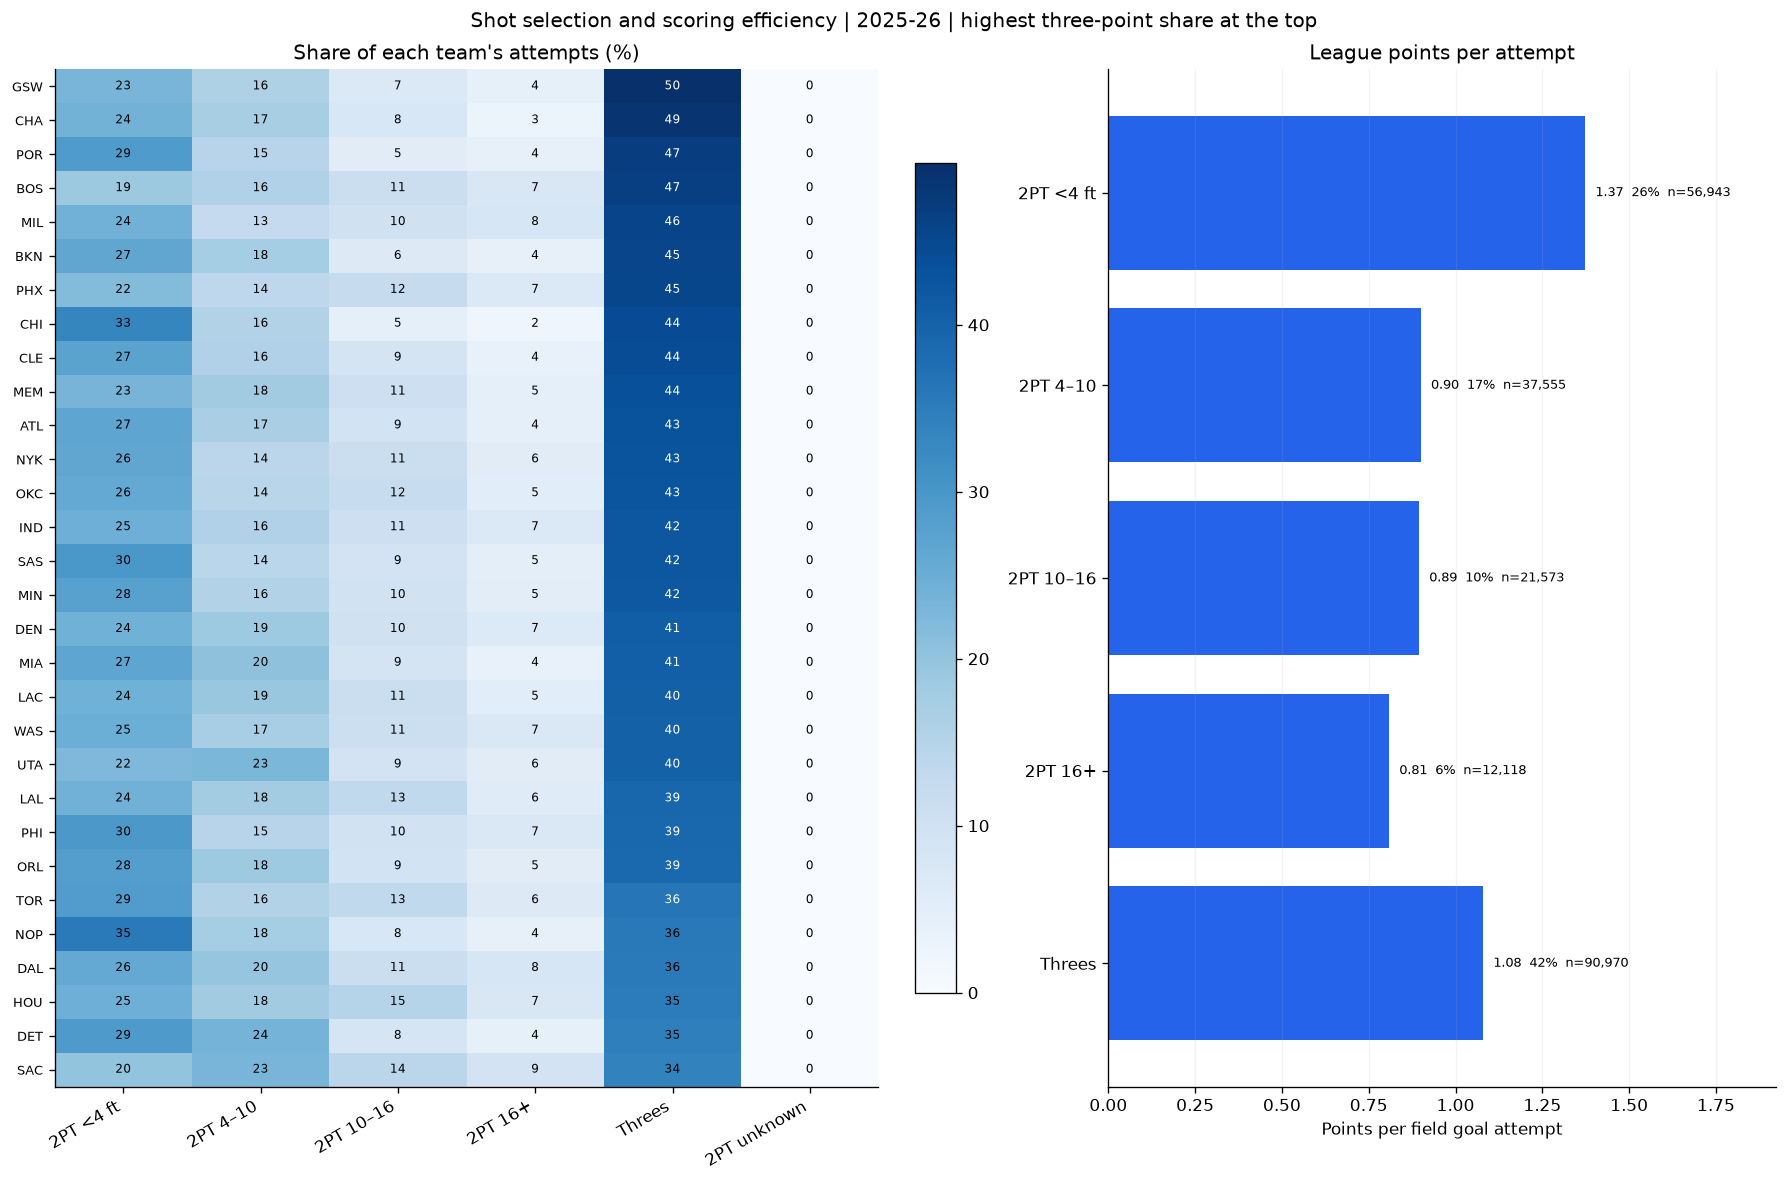

In [24]:
plot_season = PLOT_SEASON or sorted(group_summary["season"].astype(str).unique())[-1]
chart_data = group_summary.loc[group_summary["season"].astype(str).eq(str(plot_season))].copy()
team_names = sorted(chart_data["team"].astype(str).unique())
if not team_names:
    raise ValueError(f"PLOT_SEASON {plot_season!r} is not present in the selected shots.")

pooled = chart_data.groupby("shot_group", as_index=False)[["fga", "fgm", "fg3m", "points"]].sum()
pooled = pooled.set_index("shot_group").reindex(SHOT_GROUP_ORDER)
for column in ["fga", "fgm", "fg3m", "points"]:
    pooled[column] = pooled[column].fillna(0)
if int(pooled["fga"].sum()) != int(chart_data["fga"].sum()):
    raise ValueError("League attempt counts do not reconcile to the team groups.")
rate_rows = []
for row in pooled.itertuples():
    if row.fga > 0:
        rate_rows.append(field_goal_rates(row.fga, row.fgm, row.fg3m, row.points))
    else:
        rate_rows.append({"fg_pct": np.nan, "ppa": np.nan, "efg_pct": np.nan})
pooled = pooled.join(pd.DataFrame(rate_rows, index=pooled.index))
pooled["shot_share"] = pooled["fga"] / pooled["fga"].sum()
league_summary = pooled.reset_index()
display(
    league_summary.style.format(
        {
            "fga": "{:.0f}",
            "fgm": "{:.0f}",
            "fg3m": "{:.0f}",
            "points": "{:.0f}",
            "fg_pct": "{:.1%}",
            "efg_pct": "{:.1%}",
            "shot_share": "{:.1%}",
            "ppa": "{:.3f}",
        }
    ).hide(axis="index")
)

if len(team_names) <= 4:
    y = np.arange(len(SHOT_GROUP_ORDER))
    bar_height = 0.75 / len(team_names)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
    for index, (team, color) in enumerate(zip(team_names, TEAM_COLORS)):
        metrics = (
            chart_data.loc[chart_data["team"].astype(str).eq(team)]
            .set_index("shot_group")
            .reindex(SHOT_GROUP_ORDER)
        )
        positions = y + (index - (len(team_names) - 1) / 2) * bar_height
        axes[0].barh(
            positions,
            metrics["shot_share"].fillna(0) * 100,
            height=bar_height * 0.92,
            color=color,
            label=team,
        )
        present = metrics["fga"].fillna(0).gt(0).to_numpy()
        axes[1].barh(
            positions[present],
            metrics["ppa"].to_numpy(dtype=float)[present],
            height=bar_height * 0.92,
            color=color,
        )
        for position, (_, row) in zip(positions, metrics.iterrows()):
            if pd.notna(row["ppa"]):
                axes[1].text(
                    row["ppa"] + 0.03,
                    position,
                    f"{row['ppa']:.2f} (n={int(row['fga']):,})",
                    va="center",
                    fontsize=8,
                )
    axes[0].set_yticks(y, [SHORT_GROUP[name] for name in SHOT_GROUP_ORDER])
    axes[0].invert_yaxis()
    axes[0].set(title="Which shots do teams take?", xlabel="Share of team attempts (%)")
    axes[1].set(title="How efficiently do they score?", xlabel="Points per field goal attempt")
    axes[1].set_xlim(0, max(1.6, float(chart_data["ppa"].max()) + 0.65))
    for axis in axes:
        axis.set_axisbelow(True)
        axis.grid(axis="x", alpha=0.15)
    axes[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"Shot selection and scoring efficiency | {plot_season}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "shot_profile.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    share = (
        chart_data.pivot(index="team", columns="shot_group", values="shot_share")
        .reindex(columns=SHOT_GROUP_ORDER)
        .fillna(0)
        .sort_values("Three-pointers", ascending=False)
    )
    values = share.to_numpy(dtype=float) * 100
    league_plot = league_summary.loc[league_summary["fga"].gt(0)].copy()
    league_plot["_order"] = league_plot["shot_group"].map(
        {name: index for index, name in enumerate(SHOT_GROUP_ORDER)}
    )
    league_plot = league_plot.sort_values("_order")
    fig, axes = plt.subplots(
        1, 2, figsize=(15, 10), gridspec_kw={"width_ratios": [1.35, 1]}
    )
    image = axes[0].imshow(values, aspect="auto", cmap="Blues", vmin=0, vmax=max(values.max(), 1))
    axes[0].set_xticks(
        np.arange(len(share.columns)),
        [SHORT_GROUP[name] for name in share.columns],
        rotation=30,
        ha="right",
    )
    axes[0].set_yticks(np.arange(len(share.index)), share.index)
    axes[0].tick_params(axis="y", labelsize=8)
    threshold = values.max() * 0.72
    for row_index in range(values.shape[0]):
        for column_index in range(values.shape[1]):
            axes[0].text(
                column_index,
                row_index,
                f"{values[row_index, column_index]:.0f}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if values[row_index, column_index] >= threshold else "black",
            )
    axes[0].set_title("Share of each team's attempts (%)")
    fig.colorbar(image, ax=axes[0], fraction=0.046, pad=0.04)
    y = np.arange(len(league_plot))
    axes[1].barh(y, league_plot["ppa"], color="#2563eb")
    for position, row in zip(y, league_plot.itertuples(index=False)):
        axes[1].text(
            row.ppa + 0.03,
            position,
            f"{row.ppa:.2f}  {row.shot_share:.0%}  n={int(row.fga):,}",
            va="center",
            fontsize=8,
        )
    axes[1].set_yticks(y, [SHORT_GROUP[name] for name in league_plot["shot_group"]])
    axes[1].invert_yaxis()
    axes[1].set_xlim(0, float(league_plot["ppa"].max()) + 0.55)
    axes[1].set(title="League points per attempt", xlabel="Points per field goal attempt")
    axes[1].grid(axis="x", alpha=0.15)
    fig.suptitle(
        f"Shot selection and scoring efficiency | {plot_season} | highest three-point share at the top"
    )
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "shot_profile.png", dpi=180, bbox_inches="tight")
    plt.show()

## 6. Compare team scoring rates

Each bar uses that team's makes and attempts in the chart season. The games label is the coverage check. The axis spans the observed team range so gaps between teams are visible. When the filter contains more than one season, this cell also draws the season comparison.

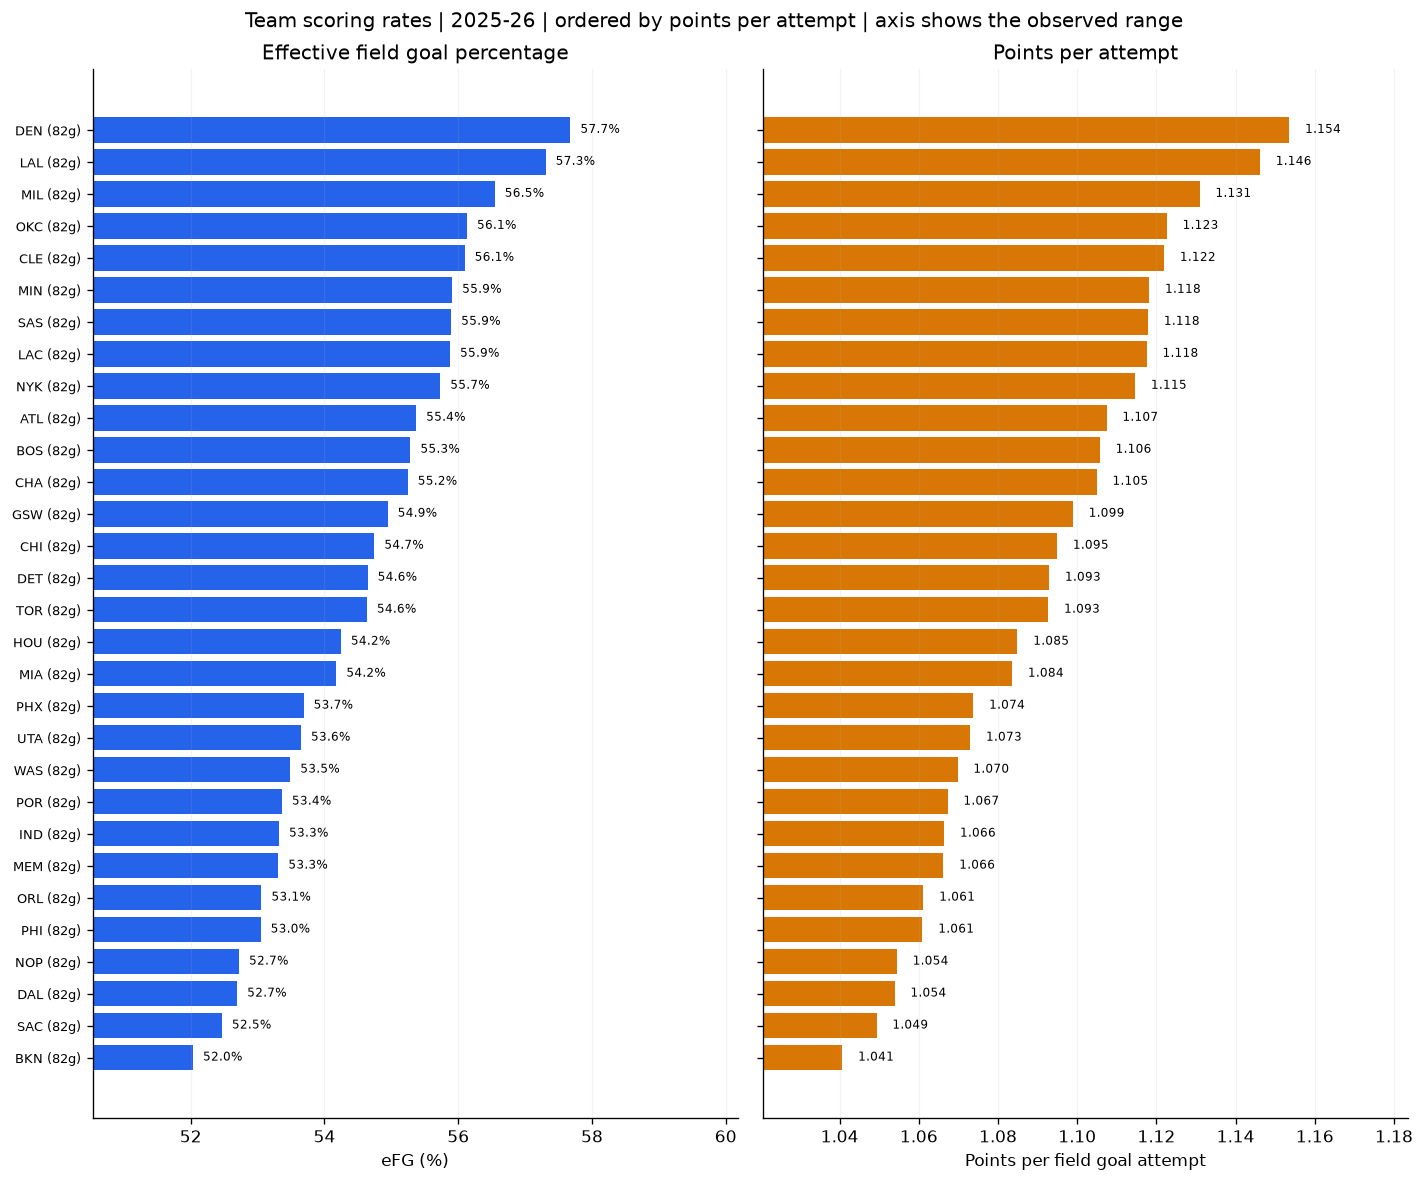

Season trend chart skipped: the scoped data has one season (2025-26).


In [25]:
season_rows = team_summary.loc[team_summary["season"].astype(str).eq(str(plot_season))].sort_values(
    ["ppa", "team"], ascending=[True, True]
)
if season_rows.empty:
    raise ValueError(f"PLOT_SEASON {plot_season!r} is not present in the team summary.")

fig, axes = plt.subplots(1, 2, figsize=(12, 10), sharey=True)
y = np.arange(len(season_rows))
labels = [f"{team} ({int(games)}g)" for team, games in zip(season_rows["team"], season_rows["games"])]
axes[0].barh(y, season_rows["efg_pct"] * 100, color="#2563eb")
axes[1].barh(y, season_rows["ppa"], color="#d97706")
for position, row in zip(y, season_rows.itertuples(index=False)):
    axes[0].text(row.efg_pct * 100 + 0.15, position, f"{row.efg_pct:.1%}", va="center", fontsize=7)
    axes[1].text(row.ppa + 0.004, position, f"{row.ppa:.3f}", va="center", fontsize=7)
axes[0].set_yticks(y, labels)
axes[0].tick_params(axis="y", labelsize=8)
efg_values = season_rows["efg_pct"] * 100
axes[0].set_xlim(float(efg_values.min()) - 1.5, float(efg_values.max()) + 2.5)
axes[1].set_xlim(float(season_rows["ppa"].min()) - 0.02, float(season_rows["ppa"].max()) + 0.03)
axes[0].set(xlabel="eFG (%)", title="Effective field goal percentage")
axes[1].set(xlabel="Points per field goal attempt", title="Points per attempt")
for axis in axes:
    axis.grid(axis="x", alpha=0.15)
fig.suptitle(f"Team scoring rates | {plot_season} | ordered by points per attempt | axis shows the observed range")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "team_efficiency.png", dpi=180, bbox_inches="tight")
plt.show()

seasons = sorted(team_summary["season"].astype(str).unique())
comparison_teams = sorted(team_summary["team"].astype(str).unique())
if len(seasons) == 1:
    print(f"Season trend chart skipped: the scoped data has one season ({plot_season}).")
elif len(comparison_teams) <= 4:
    fig, axis = plt.subplots(figsize=(9, 4))
    for team, color in zip(comparison_teams, TEAM_COLORS):
        series = (
            team_summary.loc[team_summary["team"].astype(str).eq(team)]
            .astype({"season": str})
            .set_index("season")
            .reindex(seasons)
        )
        axis.plot(seasons, series["efg_pct"] * 100, marker="o", color=color, label=team)
    axis.set(
        title="Effective field goal percentage by season",
        xlabel="Season",
        ylabel="eFG (%)",
        ylim=(0, 100),
    )
    axis.grid(axis="y", alpha=0.15)
    axis.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "season_efg.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    efg_grid = (
        team_summary.assign(season=team_summary["season"].astype(str))
        .pivot(index="team", columns="season", values="efg_pct")
        .reindex(columns=seasons)
        .sort_index()
    )
    values = efg_grid.to_numpy(dtype=float) * 100
    finite = values[np.isfinite(values)]
    fig, axis = plt.subplots(figsize=(1.6 * len(seasons) + 3, 0.32 * len(efg_grid) + 2))
    image = axis.imshow(
        values,
        aspect="auto",
        cmap="Blues",
        vmin=float(finite.min()) - 1,
        vmax=float(finite.max()) + 1,
    )
    axis.set_xticks(np.arange(len(efg_grid.columns)), efg_grid.columns, rotation=30, ha="right")
    axis.set_yticks(np.arange(len(efg_grid.index)), efg_grid.index)
    axis.tick_params(axis="y", labelsize=8)
    axis.set_title("Effective field goal percentage by team and season")
    fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "season_efg.png", dpi=180, bbox_inches="tight")
    plt.show()

## 7. Court maps

`xLegacy` and `yLegacy` are tenths of a foot. The origin is the center of the basket, positive y runs toward half court, and the baseline is 5.25 feet behind the rim. Every attempt in this extract is stored relative to the offensive basket, so the drawing is one half court. Left and right follow the source coordinates.

`COURT_TEAMS` is the published comparison: Golden State, Sacramento, Denver, and Brooklyn. Set it to `None` to draw every team in the chart season, or to another tuple of one to four teams.

The first map is where those teams shoot. Color is each square's share of that team's mapped half-court attempts. Shots with missing coordinates, and shots past half court, stay out of that share and are counted by team in the coverage table. The color scale is compressed so the arc stays visible beside the rim.

The efficiency map is points per attempt on squares about 2 feet wide. Squares with fewer than 20 mapped attempts are blank. The last map is scoring volume, the points in each square foot, not a rate.

Corner threes in the table start at 21 feet from the basket along the left-right axis, one foot inside the corner line drawn at 22 feet. A three just inside the drawn line still counts as a corner. `(0, 0)` can be a real rim attempt. Rows at `(0, 0)` with a recorded distance of 4 feet or more are shown and kept.


Chart season 2025-26: 219,159 attempts. Missing coordinates, left off the map: 0. Past the half-court lines, left off the map: 29 attempts, 45 points.
Where shotDistance > 0, |coordinate distance - shotDistance| median 0.25 ft, 95th percentile 0.48 ft, 0 attempts off by more than 2 ft.
shotDistance is 0 on 22,335 attempts (7,909 within 4 ft of the rim, 14,426 farther out). Those coordinates stay on the map.
Attempts at (0, 0): 6,025, of which shotDistance >= 4 ft: 0. A (0, 0) coordinate can be a real rim attempt. Conflicting rows are shown and kept.


,teamTricode,xLegacy,yLegacy,points,shot_value,shotDistance,x_ft,y_ft,on_court


Corner table cutoff is 21 ft from center court. The line drawn on the court is the rulebook corner at 22 ft.


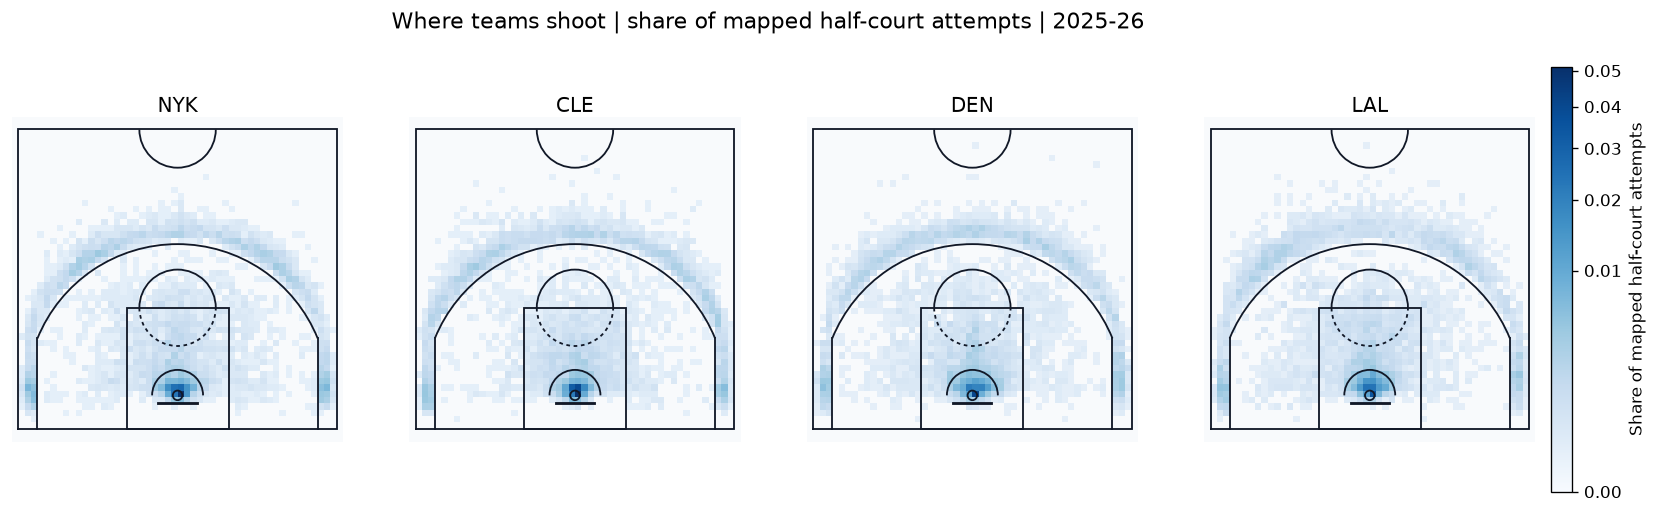

### Court finding, 2025-26
Attempt shares use mapped half-court attempts only. Shots past half court and shots with missing coordinates stay in the coverage table.
- **CLE** has the highest share above the break (33.4%, 1.064 points per attempt).
- **NYK** has the highest corner share (13.5%, 1.246 points per attempt).
- **DEN** has the highest midrange share (11.6%, 0.903 points per attempt).
The points map is scoring volume. The efficiency map is points per attempt, and it leaves out squares under the attempt minimum.

team,attempts,mapped,missing coordinates,past half court,excluded,excluded points,efficiency squares shown,efficiency squares hidden
NYK,7328,7328,0,0,0,0,92,267
CLE,7381,7380,0,1,1,0,104,266
DEN,7196,7193,0,3,3,9,92,278
LAL,6863,6862,0,1,1,0,101,287


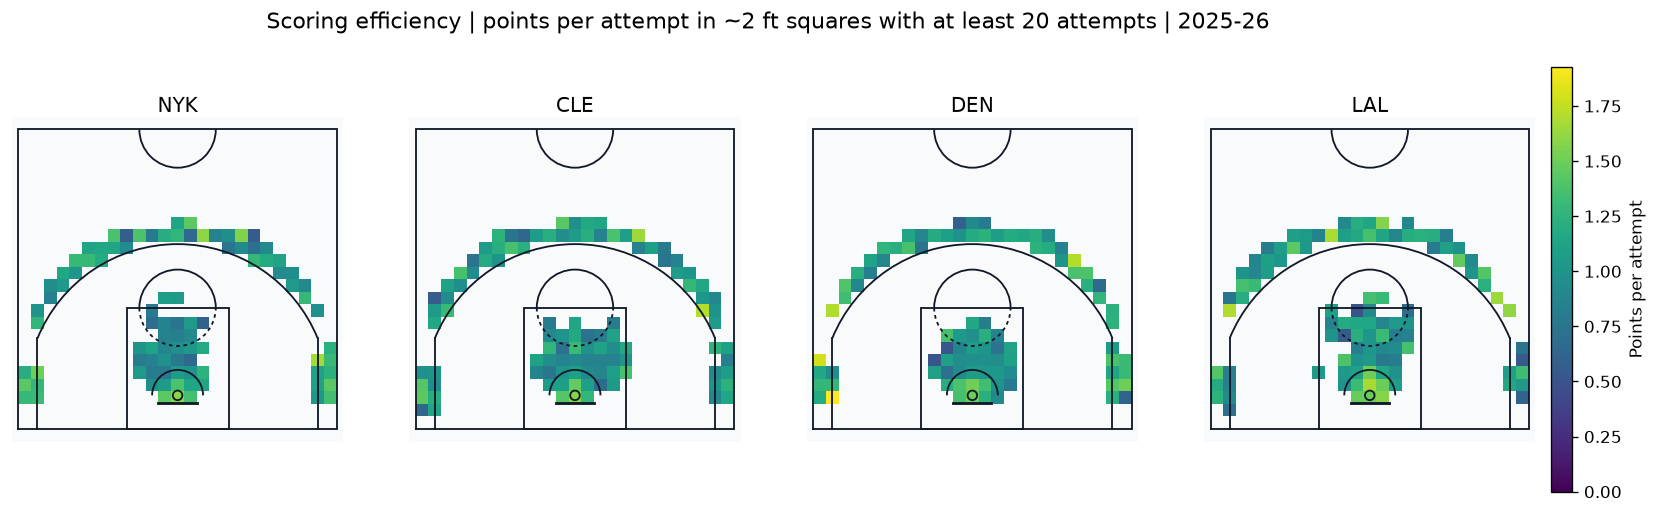

Efficiency squares under 20 attempts are blank. Hidden squares: 1,098. Shown squares: 389.


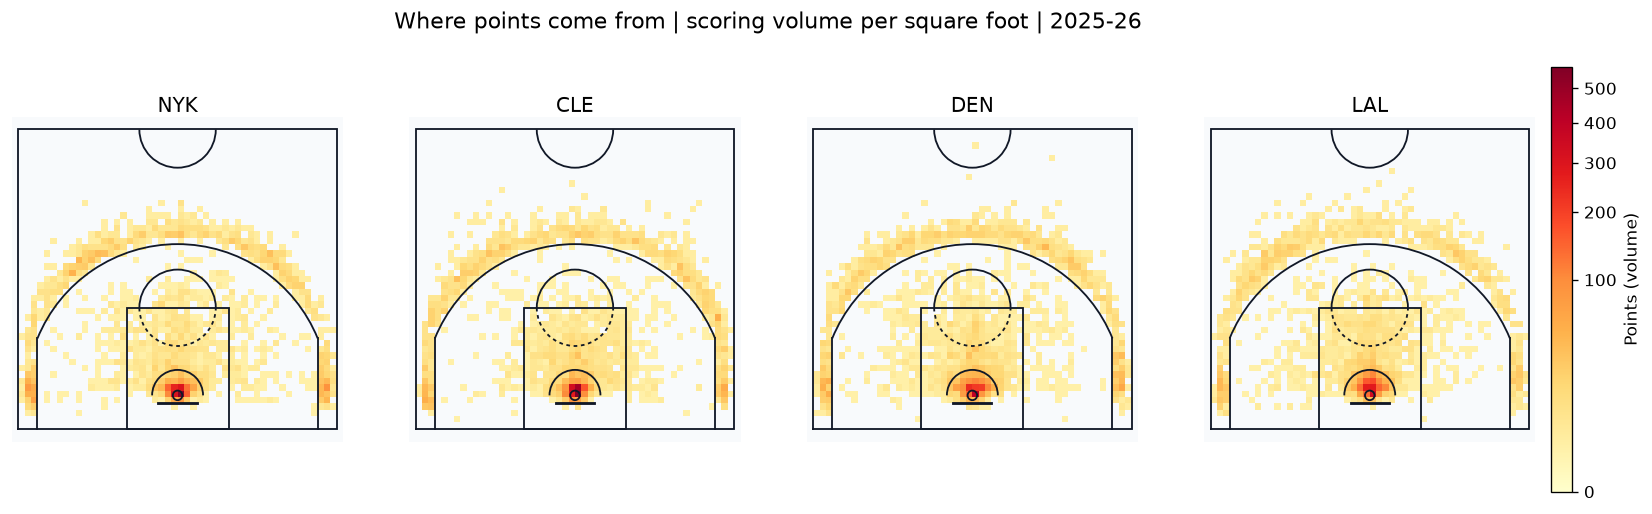

team,mapped attempts,at the rim share,at the rim points,at the rim ppa,paint share,paint points,paint ppa,midrange share,midrange points,midrange ppa,corner three share,corner three points,corner three ppa,above the break share,above the break points,above the break ppa,peak_x_ft,peak_y_ft,top square,top square points,most points
NYK,7328,28.2%,2738,1.327,17.6%,1178,0.912,11.5%,748,0.890,13.5%,1236,1.246,29.2%,2268,1.059,0.50,0.25,"(0.50, 0.25) ft",540,at the rim
CLE,7380,28.8%,2884,1.357,19.5%,1376,0.956,7.5%,502,0.905,10.8%,894,1.126,33.4%,2625,1.064,0.50,0.25,"(0.50, 0.25) ft",570,at the rim
DEN,7193,26.9%,2640,1.366,20.7%,1422,0.953,11.6%,756,0.903,10.9%,1038,1.322,29.8%,2436,1.135,0.50,0.25,"(0.50, 0.25) ft",408,at the rim
LAL,6862,26.8%,2738,1.488,22.4%,1518,0.987,11.4%,700,0.893,10.1%,723,1.045,29.3%,2187,1.089,0.50,0.25,"(0.50, 0.25) ft",332,at the rim


The highest-point square is (0.50, 0.25) ft for every plotted team with a make. Region totals still differ, and those totals are what 'most points' uses.
Saved court_attempts.png, court_efficiency.png, court_points.png, court_coverage.csv, and court_regions.csv to /Users/alexgonzalez/Documents/nba_quant/data/eda/shot_selection


In [31]:
from matplotlib.colors import PowerNorm
from matplotlib.patches import Arc, Circle, Rectangle

# Published charts use two to four teams. None draws every team in the chart season.
# These four are the 2025-26 ends of three-point share (GSW, SAC) and team points per attempt (DEN, BKN).
COURT_TEAMS = ("NYK", "CLE", "DEN", "LAL")
COURT_GAMMA = 0.4  # below 1 keeps the arc visible next to the rim on the volume and attempt maps
ATTEMPT_SHARE_LABEL = "Share of mapped half-court attempts"
PPA_MIN_ATTEMPTS = 20
PPA_BIN_FT = 2.0

BASELINE_FT = -(4 + 1.25)  # backboard is 4 ft from the baseline; rim is 1.25 ft off the backboard
HALFCOURT_FT = 47 + BASELINE_FT
FT_LINE_FT = 19 + BASELINE_FT  # free-throw line is 15 ft from the backboard, 19 ft from the baseline
THREE_RADIUS_FT = 23.75
CORNER_X_FT = 22.0  # rulebook corner line, drawn on the court
# Region label sits one foot inside the drawn line so a three just inside 22 ft still counts as a corner.
CORNER_REGION_X_FT = 21.0
CORNER_Y_FT = float(np.sqrt(THREE_RADIUS_FT**2 - CORNER_X_FT**2))
RIM_FT = 4.0
X_EDGES = np.linspace(-25, 25, 51)
Y_EDGES = np.linspace(BASELINE_FT, HALFCOURT_FT, 48)
X_EDGES_PPA = np.linspace(-25, 25, int(round(50 / PPA_BIN_FT)) + 1)
Y_EDGES_PPA = np.linspace(BASELINE_FT, HALFCOURT_FT, int(round((HALFCOURT_FT - BASELINE_FT) / PPA_BIN_FT)) + 1)


def legacy_to_feet(x_legacy, y_legacy):
    """nba_api legacy coordinates are tenths of a foot from the basket."""
    x_ft = pd.to_numeric(x_legacy, errors="coerce") / 10
    y_ft = pd.to_numeric(y_legacy, errors="coerce") / 10
    return x_ft.astype(float), y_ft.astype(float)


def on_halfcourt(x_ft, y_ft):
    finite = np.isfinite(x_ft) & np.isfinite(y_ft)
    return finite & x_ft.between(-25, 25) & y_ft.between(BASELINE_FT, HALFCOURT_FT)


def origin_distance_conflict(x_ft, y_ft, reported_distance):
    """(0, 0) with a recorded distance of at least 4 ft. Kept until reviewed."""
    return x_ft.eq(0) & y_ft.eq(0) & reported_distance.ge(4)


def bin_weights(x_ft, y_ft, weights, x_edges=None, y_edges=None):
    """Return a grid shaped (y bins, x bins), ready for imshow(origin='lower')."""
    x_edges = X_EDGES if x_edges is None else x_edges
    y_edges = Y_EDGES if y_edges is None else y_edges
    grid, _, _ = np.histogram2d(
        np.asarray(x_ft, dtype=float),
        np.asarray(y_ft, dtype=float),
        bins=[x_edges, y_edges],
        weights=None if weights is None else np.asarray(weights, dtype=float),
    )
    return grid.T


def bin_center(grid, x_edges=None, y_edges=None):
    x_edges = X_EDGES if x_edges is None else x_edges
    y_edges = Y_EDGES if y_edges is None else y_edges
    values = np.asarray(grid, dtype=float)
    if values.size == 0 or not np.isfinite(values).any() or np.nanmax(values) <= 0:
        raise ValueError("bin_center needs a grid with a positive value.")
    iy, ix = np.unravel_index(int(np.nanargmax(values)), values.shape)
    x_mid = (x_edges[ix] + x_edges[ix + 1]) / 2
    y_mid = (y_edges[iy] + y_edges[iy + 1]) / 2
    return float(x_mid), float(y_mid), float(values[iy, ix])


def peak_square(point_grid, x_edges=None, y_edges=None):
    """Coordinates of the highest-point square. An all-zero grid has no made field goals."""
    values = np.asarray(point_grid, dtype=float)
    if values.size == 0 or not np.isfinite(values).any() or np.nanmax(values) <= 0:
        return np.nan, np.nan, "no made field goals", 0
    peak_x, peak_y, peak_points = bin_center(values, x_edges, y_edges)
    return peak_x, peak_y, f"({peak_x:.2f}, {peak_y:.2f}) ft", int(round(peak_points))


def attempt_shares(attempt_grid):
    """Share of mapped half-court attempts. The grid must already exclude off-court shots."""
    total = float(np.asarray(attempt_grid).sum())
    if total <= 0:
        raise ValueError("Cannot share an empty mapped-attempt grid.")
    return np.asarray(attempt_grid, dtype=float) / total


def points_per_attempt(attempt_grid, point_grid, min_attempts):
    attempts = np.asarray(attempt_grid, dtype=float)
    points = np.asarray(point_grid, dtype=float)
    ppa = np.full(attempts.shape, np.nan, dtype=float)
    enough = attempts >= min_attempts
    ppa[enough] = points[enough] / attempts[enough]
    return ppa


def require_mapped_attempts(teams, frame):
    counts = frame["teamTricode"].astype(str).value_counts()
    empty = [team for team in teams if int(counts.get(team, 0)) == 0]
    if empty:
        raise ValueError(f"No mapped half-court attempts for {empty}. They were not drawn.")


def shot_region(x_ft, y_ft, shot_value):
    """Corner threes use CORNER_REGION_X_FT (21), one foot inside the line drawn at CORNER_X_FT (22)."""
    x = np.asarray(x_ft, dtype=float)
    y = np.asarray(y_ft, dtype=float)
    value = np.asarray(shot_value)
    distance = np.hypot(x, y)
    region = np.full(x.shape, "midrange", dtype=object)
    in_paint = (np.abs(x) <= 8) & (y <= FT_LINE_FT) & (distance >= RIM_FT)
    region[in_paint] = "paint"
    region[distance < RIM_FT] = "at the rim"
    threes = (value == 3) & (distance >= RIM_FT)
    region[threes] = "above the break"
    corners = threes & (y <= CORNER_Y_FT) & (np.abs(x) >= CORNER_REGION_X_FT)
    region[corners] = "corner three"
    return region


def draw_halfcourt(ax, lw=0.8):
    ink = "#111827"
    ax.plot(
        [-25, -25, 25, 25, -25],
        [BASELINE_FT, HALFCOURT_FT, HALFCOURT_FT, BASELINE_FT, BASELINE_FT],
        color=ink, lw=lw, zorder=3, solid_joinstyle="miter",
    )
    ax.add_patch(Rectangle((-8, BASELINE_FT), 16, FT_LINE_FT - BASELINE_FT, fill=False, ec=ink, lw=lw, zorder=3))
    ax.add_patch(Arc((0, FT_LINE_FT), 12, 12, theta1=0, theta2=180, ec=ink, lw=lw, zorder=3))
    ax.add_patch(Arc((0, FT_LINE_FT), 12, 12, theta1=180, theta2=360, ec=ink, lw=lw, ls=(0, (2, 2)), zorder=3))
    ax.add_patch(Arc((0, 0), 8, 8, theta1=0, theta2=180, ec=ink, lw=lw, zorder=3))
    ax.plot([CORNER_X_FT, CORNER_X_FT], [BASELINE_FT, CORNER_Y_FT], color=ink, lw=lw, zorder=3)
    ax.plot([-CORNER_X_FT, -CORNER_X_FT], [BASELINE_FT, CORNER_Y_FT], color=ink, lw=lw, zorder=3)
    break_deg = float(np.degrees(np.arctan2(CORNER_Y_FT, CORNER_X_FT)))
    ax.add_patch(
        Arc((0, 0), THREE_RADIUS_FT * 2, THREE_RADIUS_FT * 2, theta1=break_deg, theta2=180 - break_deg, ec=ink, lw=lw, zorder=3)
    )
    ax.add_patch(Arc((0, HALFCOURT_FT), 12, 12, theta1=180, theta2=360, ec=ink, lw=lw, zorder=3))
    ax.plot([-3, 3], [-1.25, -1.25], color=ink, lw=lw + 0.6, zorder=4)
    ax.add_patch(Circle((0, 0), 0.75, fill=False, ec=ink, lw=lw, zorder=4))
    ax.set_xlim(-26, 26)
    ax.set_ylim(BASELINE_FT - 2, HALFCOURT_FT + 2)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor("#f8fafc")
    for spine in ax.spines.values():
        spine.set_visible(False)


def paint_teams(teams, grids, title, cbar_label, cmap, path, x_edges=None, y_edges=None, norm=None, mask_nonpositive=True):
    x_edges = X_EDGES if x_edges is None else x_edges
    y_edges = Y_EDGES if y_edges is None else y_edges
    n = len(teams)
    if n <= 4:
        cols = n
        rows = 1
        fig_w, fig_h, lw = max(4.2 * n, 5), 4.6, 1.1
    else:
        cols = 6
        rows = int(np.ceil(n / cols))
        fig_w, fig_h, lw = 2.55 * cols, 2.45 * rows + 0.6, 0.55
    fig, axes = plt.subplots(rows, cols, figsize=(fig_w, fig_h), squeeze=False)
    finite = np.concatenate([np.asarray(grid)[np.isfinite(grid)] for grid in grids])
    if finite.size == 0:
        raise ValueError(f"No values to draw for {title}.")
    if norm is None:
        peak = float(np.max(finite))
        if peak <= 0:
            raise ValueError(f"Court grid has no positive bins to draw for {title}.")
        norm = PowerNorm(gamma=COURT_GAMMA, vmin=0, vmax=peak)
    image = None
    for ax, team, grid in zip(axes.ravel(), teams, grids):
        shown = np.ma.masked_invalid(np.asarray(grid, dtype=float))
        # Zero points or zero attempts are empty squares. A zero points-per-attempt is a real rate.
        if mask_nonpositive:
            shown = np.ma.masked_where(np.ma.getdata(shown) <= 0, shown)
        image = ax.imshow(
            shown, origin="lower",
            extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
            cmap=cmap, norm=norm, interpolation="nearest", zorder=1,
        )
        draw_halfcourt(ax, lw=lw)
        ax.set_title(team, fontsize=9 if n > 4 else 12, pad=2)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    if image is None:
        raise ValueError(f"No team axes to draw for {title}.")
    fig.colorbar(image, ax=axes.ravel().tolist(), fraction=0.015, pad=0.01, label=cbar_label)
    for ax in axes.ravel()[:n]:
        ax.set_aspect("equal", adjustable="box")
    fig.suptitle(title, fontsize=13)
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    return fig


_x, _y = legacy_to_feet(pd.Series([0, 220, -250]), pd.Series([0, 0, -52.5]))
if not np.allclose(_x.tolist(), [0, 22, -25]) or not np.allclose(_y.tolist(), [0, 0, -5.25]):
    raise AssertionError(f"legacy_to_feet failed: {_x.tolist()} {_y.tolist()}")
if abs(np.hypot(CORNER_X_FT, CORNER_Y_FT) - THREE_RADIUS_FT) > 1e-9:
    raise AssertionError("Corner three-point line does not meet the arc.")
if CORNER_REGION_X_FT >= CORNER_X_FT:
    raise AssertionError("The corner region cutoff must sit inside the drawn 22 ft line.")
_corner = bin_weights(pd.Series([22.0]), pd.Series([0.0]), None)
_x22, _y0, _n22 = bin_center(_corner)
if abs(_x22 - 22.5) > 1e-6 or abs(_y0 - 0.25) > 1e-6 or _n22 != 1:
    raise AssertionError(f"Bin orientation failed for the corner: {_x22}, {_y0}, {_n22}")
_high = bin_weights(pd.Series([0.0]), pd.Series([20.0]), None)
_x0, _y20, _n20 = bin_center(_high)
if abs(_x0 - 0.5) > 1e-6 or abs(_y20 - 20.25) > 1e-6 or _n20 != 1:
    raise AssertionError(f"Bin orientation failed for (0, 20): {_x0}, {_y20}, {_n20}")
# A corner three can be closer than the 23.75 ft arc. Distance must not relabel it as a two.
if not (np.hypot(22, 2) < THREE_RADIUS_FT):
    raise AssertionError("The corner fixture should sit inside the above-the-break radius.")
_regions = shot_region(
    [0, 0, 0, 22, 0, 22, 21, 20.9],
    [0, 8, 18, 2, 25, 2, 2, 2],
    [2, 2, 2, 3, 3, 2, 3, 3],
)
_expected_regions = [
    "at the rim", "paint", "midrange", "corner three", "above the break", "midrange",
    "corner three", "above the break",
]
if list(_regions) != _expected_regions:
    raise AssertionError(f"Regions {list(_regions)} != {_expected_regions}")
_edge = on_halfcourt(pd.Series([25.0, 0.0, 0.0]), pd.Series([HALFCOURT_FT, HALFCOURT_FT + 0.01, BASELINE_FT - 0.01]))
if list(_edge) != [True, False, False]:
    raise AssertionError(f"Half-court mask failed: {list(_edge)}")
_conflict = origin_distance_conflict(
    pd.Series([0.0, 0.0, 1.0]), pd.Series([0.0, 0.0, 0.0]), pd.Series([10.0, 0.0, 10.0]),
)
if list(_conflict) != [True, False, False]:
    raise AssertionError(f"Origin conflict mask failed: {list(_conflict)}")
_zero = np.zeros((len(Y_EDGES) - 1, len(X_EDGES) - 1))
_px, _py, _label, _pts = peak_square(_zero)
if not (np.isnan(_px) and np.isnan(_py) and _label == "no made field goals" and _pts == 0):
    raise AssertionError(f"Scoreless grid was labeled {_label} at ({_px}, {_py})")
try:
    bin_center(_zero)
    raise AssertionError("bin_center should refuse an all-zero grid.")
except ValueError:
    pass
_peak_x, _peak_y, _peak_label, _peak_pts = peak_square(bin_weights(pd.Series([22.0]), pd.Series([0.0]), pd.Series([3.0])))
if _peak_label != "(22.50, 0.25) ft" or _peak_pts != 3:
    raise AssertionError(f"Peak square label failed: {_peak_label} {_peak_pts}")
_same = pd.DataFrame({"peak_x_ft": [0.5, 0.5], "peak_y_ft": [0.25, 0.25]})
_different = pd.DataFrame({"peak_x_ft": [0.5, 0.5], "peak_y_ft": [0.25, 1.25]})
if _same[["peak_x_ft", "peak_y_ft"]].drop_duplicates().shape[0] != 1:
    raise AssertionError("Identical squares did not collapse.")
if _different[["peak_x_ft", "peak_y_ft"]].drop_duplicates().shape[0] != 2:
    raise AssertionError("Neighboring rim squares were treated as the same square.")
_share = attempt_shares(np.array([[1.0, 0.0], [3.0, 0.0]]))
if not np.isclose(_share.sum(), 1) or not np.isclose(_share[1, 0], 0.75):
    raise AssertionError(f"Attempt shares failed: {_share}")
try:
    attempt_shares(np.zeros((2, 2)))
    raise AssertionError("Empty attempt grid should have been rejected.")
except ValueError:
    pass
_ppa = points_per_attempt(np.array([[1.0, 4.0], [0.0, 20.0]]), np.array([[3.0, 4.0], [0.0, 20.0]]), min_attempts=2)
if not (np.isnan(_ppa[0, 0]) and np.isnan(_ppa[1, 0]) and np.isclose(_ppa[0, 1], 1) and np.isclose(_ppa[1, 1], 1)):
    raise AssertionError(f"Points per attempt mask failed: {_ppa}")
try:
    require_mapped_attempts(["AAA"], pd.DataFrame({"teamTricode": ["BBB"]}))
    raise AssertionError("A team with no mapped attempts should have been rejected.")
except ValueError as exc:
    if "AAA" not in str(exc):
        raise
if "mapped half-court" not in ATTEMPT_SHARE_LABEL:
    raise AssertionError("Attempt colorbar must name the mapped half-court denominator.")
if not np.allclose(np.diff(X_EDGES_PPA), PPA_BIN_FT):
    raise AssertionError(f"Efficiency bins are not {PPA_BIN_FT} ft wide.")

court = shots.loc[
    shots["season"].astype("string").eq(str(plot_season)),
    ["teamTricode", "xLegacy", "yLegacy", "points", "shot_value", "shotDistance"],
].copy()
court["x_ft"], court["y_ft"] = legacy_to_feet(court["xLegacy"], court["yLegacy"])
court["on_court"] = on_halfcourt(court["x_ft"], court["y_ft"])
missing_xy = int((~np.isfinite(court["x_ft"]) | ~np.isfinite(court["y_ft"])).sum())
off_court = court.loc[np.isfinite(court["x_ft"]) & np.isfinite(court["y_ft"]) & ~court["on_court"]]
print(
    f"Chart season {plot_season}: {len(court):,} attempts. "
    f"Missing coordinates, left off the map: {missing_xy:,}. "
    f"Past the half-court lines, left off the map: {len(off_court):,} attempts, "
    f"{off_court['points'].sum():,.0f} points."
)
reported = pd.to_numeric(court["shotDistance"], errors="coerce")
coord_distance = np.hypot(court["x_ft"], court["y_ft"])
comparable = reported.gt(0) & court["on_court"]
median_err = (coord_distance.loc[comparable] - reported.loc[comparable]).abs().median()
abs_err = (coord_distance.loc[comparable] - reported.loc[comparable]).abs()
print(
    f"Where shotDistance > 0, |coordinate distance - shotDistance| "
    f"median {median_err:.2f} ft, 95th percentile {abs_err.quantile(0.95):.2f} ft, "
    f"{int((abs_err > 2).sum()):,} attempts off by more than 2 ft."
)
if not np.isfinite(median_err) or median_err > 1:
    raise ValueError("xLegacy and yLegacy do not match shotDistance in feet. The court was not drawn.")
zero_distance = reported.eq(0)
print(
    f"shotDistance is 0 on {int(zero_distance.sum()):,} attempts "
    f"({int((zero_distance & coord_distance.le(4)).sum()):,} within 4 ft of the rim, "
    f"{int((zero_distance & coord_distance.gt(4)).sum()):,} farther out). Those coordinates stay on the map."
)
at_origin = court["x_ft"].eq(0) & court["y_ft"].eq(0)
suspect_origin = origin_distance_conflict(court["x_ft"], court["y_ft"], reported)
print(
    f"Attempts at (0, 0): {int(at_origin.sum()):,}, of which shotDistance >= 4 ft: {int(suspect_origin.sum()):,}. "
    "A (0, 0) coordinate can be a real rim attempt. Conflicting rows are shown and kept."
)
display(court.loc[suspect_origin].head(10))
print(
    f"Corner table cutoff is {CORNER_REGION_X_FT:.0f} ft from center court. "
    f"The line drawn on the court is the rulebook corner at {CORNER_X_FT:.0f} ft."
)

available = sorted(court["teamTricode"].dropna().astype(str).unique())
if COURT_TEAMS is None:
    mapped_teams = available
else:
    unknown = [team for team in COURT_TEAMS if team not in available]
    if unknown:
        raise ValueError(f"COURT_TEAMS not in {plot_season}: {unknown}. Available: {available}")
    if not 1 <= len(COURT_TEAMS) <= 4:
        raise ValueError("COURT_TEAMS must contain one to four teams, or be None for every team.")
    mapped_teams = list(COURT_TEAMS)

mapped = court.loc[court["on_court"] & court["teamTricode"].isin(mapped_teams)].copy()
require_mapped_attempts(mapped_teams, mapped)
attempt_grids = []
point_grids = []
ppa_grids = []
coverage_rows = []
for team in mapped_teams:
    team_all = court.loc[court["teamTricode"].astype(str).eq(team)]
    team_rows = mapped.loc[mapped["teamTricode"].eq(team)]
    attempts = bin_weights(team_rows["x_ft"], team_rows["y_ft"], None)
    scored = bin_weights(team_rows["x_ft"], team_rows["y_ft"], team_rows["points"])
    if int(round(attempts.sum())) != len(team_rows):
        raise AssertionError(f"{team} attempt grid does not match mapped rows.")
    if not np.isclose(scored.sum(), team_rows["points"].sum()):
        raise AssertionError(f"{team} points grid does not match mapped points.")
    ppa_attempts = bin_weights(team_rows["x_ft"], team_rows["y_ft"], None, X_EDGES_PPA, Y_EDGES_PPA)
    ppa_points = bin_weights(team_rows["x_ft"], team_rows["y_ft"], team_rows["points"], X_EDGES_PPA, Y_EDGES_PPA)
    ppa = points_per_attempt(ppa_attempts, ppa_points, PPA_MIN_ATTEMPTS)
    occupied = ppa_attempts > 0
    attempt_grids.append(attempts)
    point_grids.append(scored)
    ppa_grids.append(ppa)
    missing = ~np.isfinite(team_all["x_ft"]) | ~np.isfinite(team_all["y_ft"])
    past = np.isfinite(team_all["x_ft"]) & np.isfinite(team_all["y_ft"]) & ~team_all["on_court"]
    coverage_rows.append({
        "team": team,
        "attempts": int(len(team_all)),
        "mapped": int(team_all["on_court"].sum()),
        "missing coordinates": int(missing.sum()),
        "past half court": int(past.sum()),
        "excluded": int((~team_all["on_court"]).sum()),
        "excluded points": float(team_all.loc[~team_all["on_court"], "points"].sum()),
        "efficiency squares shown": int(np.isfinite(ppa).sum()),
        "efficiency squares hidden": int((occupied & (ppa_attempts < PPA_MIN_ATTEMPTS)).sum()),
    })
coverage_table = pd.DataFrame(coverage_rows)
if int(coverage_table["mapped"].sum()) != len(mapped):
    raise AssertionError("Per-team mapped counts do not match the half-court rows.")

attempt_title = f"Where teams shoot | {ATTEMPT_SHARE_LABEL.lower()} | {plot_season}"
paint_teams(
    mapped_teams,
    [attempt_shares(grid) for grid in attempt_grids],
    attempt_title,
    ATTEMPT_SHARE_LABEL,
    "Blues",
    OUTPUT_DIR / "court_attempts.png",
)

mapped["region"] = shot_region(mapped["x_ft"], mapped["y_ft"], mapped["shot_value"])
REGION_ORDER = ["at the rim", "paint", "midrange", "corner three", "above the break"]
region_rows = []
for team, point_grid in zip(mapped_teams, point_grids):
    team_rows = mapped.loc[mapped["teamTricode"].eq(team)]
    counts = team_rows["region"].value_counts()
    points = team_rows.groupby("region")["points"].sum()
    row = {"team": team, "mapped attempts": int(len(team_rows))}
    for name in REGION_ORDER:
        made_attempts = int(counts.get(name, 0))
        made_points = int(points.get(name, 0))
        row[f"{name} share"] = made_attempts / len(team_rows)
        row[f"{name} points"] = made_points
        row[f"{name} ppa"] = (made_points / made_attempts) if made_attempts else np.nan
    peak_x, peak_y, peak_label, peak_points = peak_square(point_grid)
    row["peak_x_ft"] = peak_x
    row["peak_y_ft"] = peak_y
    row["top square"] = peak_label
    row["top square points"] = peak_points
    best_region = max(REGION_ORDER, key=lambda name: row[f"{name} points"])
    row["most points"] = best_region
    region_rows.append(row)
region_table = pd.DataFrame(region_rows)

above_team = region_table.sort_values("above the break share", ascending=False).iloc[0]
corner_team = region_table.sort_values("corner three share", ascending=False).iloc[0]
mid_team = region_table.sort_values("midrange share", ascending=False).iloc[0]
finding = "\n".join([
    f"### Court finding, {plot_season}",
    "Attempt shares use mapped half-court attempts only. Shots past half court and shots with missing coordinates stay in the coverage table.",
    (
        f"- **{above_team['team']}** has the highest share above the break "
        f"({above_team['above the break share']:.1%}, {above_team['above the break ppa']:.3f} points per attempt)."
    ),
    (
        f"- **{corner_team['team']}** has the highest corner share "
        f"({corner_team['corner three share']:.1%}, {corner_team['corner three ppa']:.3f} points per attempt)."
    ),
    (
        f"- **{mid_team['team']}** has the highest midrange share "
        f"({mid_team['midrange share']:.1%}, {mid_team['midrange ppa']:.3f} points per attempt)."
    ),
    "The points map is scoring volume. The efficiency map is points per attempt, and it leaves out squares under the attempt minimum.",
])
display(Markdown(finding))
display(coverage_table.style.format({"excluded points": "{:.0f}"}).hide(axis="index"))
coverage_table.to_csv(OUTPUT_DIR / "court_coverage.csv", index=False)

if not any(np.isfinite(grid).any() for grid in ppa_grids):
    raise ValueError(
        f"No square reached {PPA_MIN_ATTEMPTS} attempts, so the efficiency map was not drawn."
    )
ppa_finite = np.concatenate([grid[np.isfinite(grid)] for grid in ppa_grids])
ppa_norm = plt.Normalize(vmin=0, vmax=float(np.max(ppa_finite)) if float(np.max(ppa_finite)) > 0 else 1)
paint_teams(
    mapped_teams,
    ppa_grids,
    f"Scoring efficiency | points per attempt in ~{PPA_BIN_FT:.0f} ft squares with at least {PPA_MIN_ATTEMPTS} attempts | {plot_season}",
    "Points per attempt",
    "viridis",
    OUTPUT_DIR / "court_efficiency.png",
    x_edges=X_EDGES_PPA,
    y_edges=Y_EDGES_PPA,
    norm=ppa_norm,
    mask_nonpositive=False,
)
print(
    f"Efficiency squares under {PPA_MIN_ATTEMPTS} attempts are blank. "
    f"Hidden squares: {int(coverage_table['efficiency squares hidden'].sum()):,}. "
    f"Shown squares: {int(coverage_table['efficiency squares shown'].sum()):,}."
)

if not any(float(np.asarray(grid).sum()) > 0 for grid in point_grids):
    raise ValueError("No made field goals on the mapped half court, so the volume map was not drawn.")
paint_teams(
    mapped_teams,
    point_grids,
    f"Where points come from | scoring volume per square foot | {plot_season}",
    "Points (volume)",
    "YlOrRd",
    OUTPUT_DIR / "court_points.png",
)

share_cols = [f"{name} share" for name in REGION_ORDER]
ppa_cols = [f"{name} ppa" for name in REGION_ORDER]
display(
    region_table.style.format(
        {**{column: "{:.1%}" for column in share_cols}, **{column: "{:.3f}" for column in ppa_cols},
         "peak_x_ft": "{:.2f}", "peak_y_ft": "{:.2f}"}
    ).hide(axis="index")
)
region_table.to_csv(OUTPUT_DIR / "court_regions.csv", index=False)
scoreless = region_table.loc[region_table["peak_x_ft"].isna(), "team"].tolist()
if scoreless:
    print(f"No made field goals on the mapped half court: {scoreless}. No highest-point square is assigned.")
scored = region_table.dropna(subset=["peak_x_ft", "peak_y_ft"])
if not scored.empty:
    same_square = scored[["peak_x_ft", "peak_y_ft"]].drop_duplicates().shape[0] == 1
    if same_square:
        print(
            f"The highest-point square is ({scored['peak_x_ft'].iloc[0]:.2f}, {scored['peak_y_ft'].iloc[0]:.2f}) ft "
            "for every plotted team with a make. Region totals still differ, and those totals are what 'most points' uses."
        )
    else:
        print("The highest-point square is not the same coordinates for every plotted team.")
print(
    "Saved court_attempts.png, court_efficiency.png, court_points.png, court_coverage.csv, and court_regions.csv to",
    OUTPUT_DIR,
)

## 7b. Court sections

This is the zone chart from the NBA.com layout, built from `xLegacy` and `yLegacy`. The basket is at the top. Each box is makes/attempts and field-goal percentage. Color uses that percentage on one scale for every team.

The 14 sections are geometric. They are not official NBA shot-zone labels. A shot on the corner side of the 22-foot line is a corner three even when it is closer than the 23.75-foot arc. Above-the-break threes are split into three equal slices of that arc. Shots past half court stay out of the sections and are counted above the figure. The table adds points per attempt, because field-goal percentage treats a three the same as a two.


Zone chart season 2025-26: 219,159 attempts, 219,130 on the half court, 29 left off the sections.
206 mapped attempts are more than 32 ft from the basket toward half court. They stay in their wing totals; the drawing stops at that line.
Corner sections use the line at 22 ft. Above-the-break wings are split at ±22.6 degrees from straight upcourt.


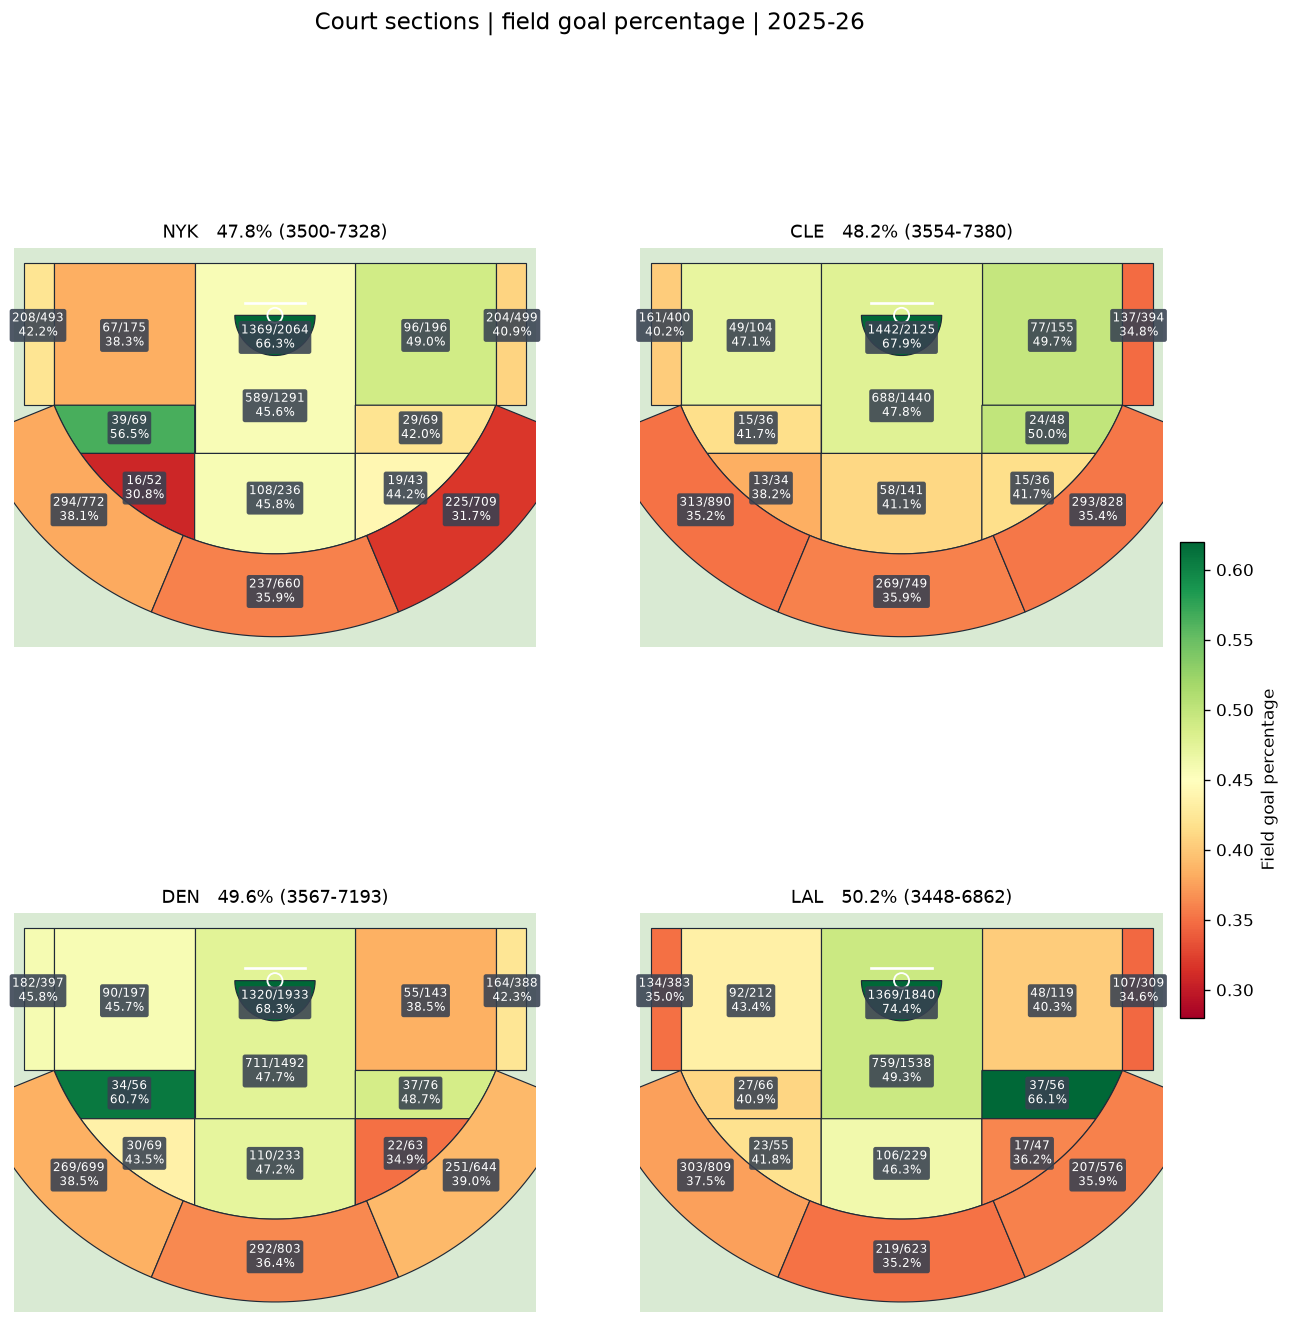

Colors are field-goal percentage, the rate printed on the NBA.com chart. Points per attempt in the table counts a three as three points.


team,section,attempts,makes,fg_pct,points,ppa
NYK,Left Corner 3,493,208,42.2%,624,1.266
NYK,Left Baseline Two,175,67,38.3%,134,0.766
NYK,Restricted Area,2064,1369,66.3%,2738,1.327
NYK,Right Baseline Two,196,96,49.0%,192,0.980
NYK,Right Corner 3,499,204,40.9%,612,1.226
NYK,Left Short Two,69,39,56.5%,78,1.130
NYK,Paint,1291,589,45.6%,1178,0.912
NYK,Right Short Two,69,29,42.0%,58,0.841
NYK,Left Elbow Two,52,16,30.8%,32,0.615
NYK,Center Two,236,108,45.8%,216,0.915


Saved court_zones.png and court_zones.csv to /Users/alexgonzalez/Documents/nba_quant/data/eda/shot_selection


In [33]:
from matplotlib.patches import Circle, Polygon
from matplotlib.path import Path as PolygonPath

# Geometric sections in the NBA.com zone-chart layout. Not official shot-zone tags.
# The corner split is the line drawn at 22 ft. Priority is the order in shot_sections.
SECTION_ORDER = [
    "Left Corner 3",
    "Left Baseline Two",
    "Restricted Area",
    "Right Baseline Two",
    "Right Corner 3",
    "Left Short Two",
    "Paint",
    "Right Short Two",
    "Left Elbow Two",
    "Center Two",
    "Right Elbow Two",
    "Left Wing 3",
    "Center 3",
    "Right Wing 3",
]
SECTION_FRAME_FT = 32.0  # drawing stops here; shots farther upcourt still count in the wing
ZONE_FG_VMIN = 0.28
ZONE_FG_VMAX = 0.62
THIRD_DEG = float(np.degrees(np.arctan2(CORNER_X_FT, CORNER_Y_FT)) / 3)
_ARC_X_AT_FT = float(np.sqrt(THREE_RADIUS_FT**2 - FT_LINE_FT**2))
_Y_AT_LANE = float(np.sqrt(THREE_RADIUS_FT**2 - 8**2))


def _arc(radius, start_deg, end_deg, n=36):
    """Points on a circle. 0 degrees is straight upcourt; positive degrees are to the right."""
    angles = np.linspace(np.radians(start_deg), np.radians(end_deg), n)
    return np.column_stack([radius * np.sin(angles), radius * np.cos(angles)])


def shot_sections(x_ft, y_ft):
    """Assign each shot to one court section from feet relative to the basket."""
    x = np.asarray(x_ft, dtype=float)
    y = np.asarray(y_ft, dtype=float)
    distance = np.hypot(x, y)
    angle = np.degrees(np.arctan2(x, y))
    section = np.full(x.shape, "unassigned", dtype=object)
    open_slot = np.ones(x.shape, dtype=bool)

    def take(mask, name):
        chosen = open_slot & mask
        section[chosen] = name
        open_slot[chosen] = False

    near_baseline = y <= CORNER_Y_FT
    take(near_baseline & (x <= -CORNER_X_FT), "Left Corner 3")
    take(near_baseline & (x >= CORNER_X_FT), "Right Corner 3")
    beyond_arc = distance >= THREE_RADIUS_FT
    take(beyond_arc & (angle < -THIRD_DEG), "Left Wing 3")
    take(beyond_arc & (angle > THIRD_DEG), "Right Wing 3")
    take(beyond_arc, "Center 3")
    take(distance < RIM_FT, "Restricted Area")
    take((np.abs(x) <= 8) & (y <= FT_LINE_FT), "Paint")
    take(near_baseline & (x < 0), "Left Baseline Two")
    take(near_baseline & (x >= 0), "Right Baseline Two")
    take((y <= FT_LINE_FT) & (x < 0), "Left Short Two")
    take((y <= FT_LINE_FT) & (x >= 0), "Right Short Two")
    take(x < -8, "Left Elbow Two")
    take(x > 8, "Right Elbow Two")
    take(np.ones(x.shape, dtype=bool), "Center Two")
    return section


def section_polygons():
    """Closed shapes for the 14 sections. Anchors used as labels must fall inside them."""
    left_corner = -float(np.degrees(np.arctan2(CORNER_X_FT, CORNER_Y_FT)))
    right_corner = -left_corner
    left_ft = float(np.degrees(np.arctan2(-_ARC_X_AT_FT, FT_LINE_FT)))
    right_ft = -left_ft
    left_lane = float(np.degrees(np.arctan2(-8, _Y_AT_LANE)))
    right_lane = -left_lane
    polygons = {
        "Left Corner 3": np.array([
            [-25, BASELINE_FT], [-CORNER_X_FT, BASELINE_FT],
            [-CORNER_X_FT, CORNER_Y_FT], [-25, CORNER_Y_FT],
        ]),
        "Right Corner 3": np.array([
            [CORNER_X_FT, BASELINE_FT], [25, BASELINE_FT],
            [25, CORNER_Y_FT], [CORNER_X_FT, CORNER_Y_FT],
        ]),
        "Left Baseline Two": np.array([
            [-CORNER_X_FT, BASELINE_FT], [-8, BASELINE_FT],
            [-8, CORNER_Y_FT], [-CORNER_X_FT, CORNER_Y_FT],
        ]),
        "Right Baseline Two": np.array([
            [8, BASELINE_FT], [CORNER_X_FT, BASELINE_FT],
            [CORNER_X_FT, CORNER_Y_FT], [8, CORNER_Y_FT],
        ]),
        "Paint": np.array([
            [-8, BASELINE_FT], [8, BASELINE_FT],
            [8, FT_LINE_FT], [-8, FT_LINE_FT],
        ]),
        "Restricted Area": np.vstack([
            _arc(RIM_FT, -90, 90),
            [[RIM_FT, 0.0], [-RIM_FT, 0.0]],
        ]),
        "Left Short Two": np.vstack([
            [[-8, CORNER_Y_FT], [-CORNER_X_FT, CORNER_Y_FT]],
            _arc(THREE_RADIUS_FT, left_corner, left_ft),
            [[-8, FT_LINE_FT]],
        ]),
        "Right Short Two": np.vstack([
            [[8, CORNER_Y_FT], [CORNER_X_FT, CORNER_Y_FT]],
            _arc(THREE_RADIUS_FT, right_corner, right_ft),
            [[8, FT_LINE_FT]],
        ]),
        "Left Elbow Two": np.vstack([
            [[-8, FT_LINE_FT], [-_ARC_X_AT_FT, FT_LINE_FT]],
            _arc(THREE_RADIUS_FT, left_ft, left_lane),
            [[-8, FT_LINE_FT]],
        ]),
        "Right Elbow Two": np.vstack([
            [[8, FT_LINE_FT], [_ARC_X_AT_FT, FT_LINE_FT]],
            _arc(THREE_RADIUS_FT, right_ft, right_lane),
            [[8, FT_LINE_FT]],
        ]),
        "Center Two": np.vstack([
            [[-8, FT_LINE_FT], [8, FT_LINE_FT]],
            _arc(THREE_RADIUS_FT, right_lane, left_lane),
        ]),
        "Left Wing 3": np.vstack([
            _arc(THREE_RADIUS_FT, left_corner, -THIRD_DEG),
            _arc(SECTION_FRAME_FT, -THIRD_DEG, left_corner),
        ]),
        "Center 3": np.vstack([
            _arc(THREE_RADIUS_FT, -THIRD_DEG, THIRD_DEG),
            _arc(SECTION_FRAME_FT, THIRD_DEG, -THIRD_DEG),
        ]),
        "Right Wing 3": np.vstack([
            _arc(THREE_RADIUS_FT, THIRD_DEG, right_corner),
            _arc(SECTION_FRAME_FT, right_corner, THIRD_DEG),
        ]),
    }
    missing = [name for name in SECTION_ORDER if name not in polygons]
    if missing:
        raise AssertionError(f"Missing section polygons: {missing}")
    return polygons


def _anchor(name):
    radius = 27.5
    side = np.radians((float(np.degrees(np.arctan2(CORNER_X_FT, CORNER_Y_FT))) + THIRD_DEG) / 2)
    anchors = {
        "Left Corner 3": (-23.6, 1.0),
        "Right Corner 3": (23.6, 1.0),
        "Left Baseline Two": (-15.0, 2.0),
        "Right Baseline Two": (15.0, 2.0),
        "Restricted Area": (0.0, 2.2),
        "Paint": (0.0, 9.0),
        "Left Short Two": (-14.5, 11.2),
        "Right Short Two": (14.5, 11.2),
        "Left Elbow Two": (-13.0, 17.2),
        "Right Elbow Two": (13.0, 17.2),
        "Center Two": (0.0, 18.2),
        "Left Wing 3": (-radius * np.sin(side), radius * np.cos(side)),
        "Center 3": (0.0, 27.5),
        "Right Wing 3": (radius * np.sin(side), radius * np.cos(side)),
    }
    return anchors[name]


_fixture_x = [0, 0, -23, 23, -15, 15, -15, 15, -13, 0, 13, -18, 0, 18]
_fixture_y = [1.6, 9, 1, 1, 2, 2, 11.2, 11.2, 17.2, 18.2, 17.2, 18, 27.5, 18]
_fixture_names = [
    "Restricted Area", "Paint", "Left Corner 3", "Right Corner 3",
    "Left Baseline Two", "Right Baseline Two", "Left Short Two", "Right Short Two",
    "Left Elbow Two", "Center Two", "Right Elbow Two", "Left Wing 3", "Center 3", "Right Wing 3",
]
_got = list(shot_sections(_fixture_x, _fixture_y))
if _got != _fixture_names:
    raise AssertionError(f"Section fixture {_got} != {_fixture_names}")
# A corner three is inside 23.75 ft. Distance must not move it into a wing.
if float(np.hypot(-22, 2)) >= THREE_RADIUS_FT:
    raise AssertionError("Corner fixture should sit inside the above-the-break arc.")
if shot_sections([-22], [2])[0] != "Left Corner 3":
    raise AssertionError("The 22 ft corner line was not applied.")
_polygons = section_polygons()
for _name, _x_anchor, _y_anchor in zip(_fixture_names, _fixture_x, _fixture_y):
    _px, _py = _anchor(_name)
    if shot_sections([_px], [_py])[0] != _name:
        raise AssertionError(f"Label for {_name} classifies as {shot_sections([_px], [_py])[0]}")
    if not PolygonPath(_polygons[_name]).contains_point((_px, _py)):
        raise AssertionError(f"Label for {_name} is outside its polygon.")
if abs(THIRD_DEG - 22.62) > 0.1:
    raise AssertionError(f"Above-the-break slices should be about 22.6 degrees, got {THIRD_DEG:.2f}")

zone_shots = shots.loc[
    shots["season"].astype("string").eq(str(plot_season)),
    ["teamTricode", "xLegacy", "yLegacy", "points"],
].copy()
zone_shots["x_ft"], zone_shots["y_ft"] = legacy_to_feet(zone_shots["xLegacy"], zone_shots["yLegacy"])
zone_shots["on_court"] = on_halfcourt(zone_shots["x_ft"], zone_shots["y_ft"])
zone_shots["made"] = zone_shots["points"].gt(0).astype(int)
print(
    f"Zone chart season {plot_season}: {len(zone_shots):,} attempts, "
    f"{int(zone_shots['on_court'].sum()):,} on the half court, "
    f"{int((~zone_shots['on_court']).sum()):,} left off the sections."
)
on_zone = zone_shots.loc[zone_shots["on_court"]].copy()
on_zone["section"] = shot_sections(on_zone["x_ft"], on_zone["y_ft"])
unassigned = on_zone["section"].eq("unassigned")
if unassigned.any():
    display(on_zone.loc[unassigned, ["teamTricode", "x_ft", "y_ft", "points"]].head(10))
    raise AssertionError(f"{int(unassigned.sum())} mapped shots did not fall in a section.")
unknown = sorted(set(on_zone["section"]) - set(SECTION_ORDER))
if unknown:
    raise AssertionError(f"Unexpected sections: {unknown}")
beyond_frame = int(on_zone["y_ft"].gt(SECTION_FRAME_FT).sum())
print(
    f"{beyond_frame:,} mapped attempts are more than {SECTION_FRAME_FT:.0f} ft from the basket "
    "toward half court. They stay in their wing totals; the drawing stops at that line."
)
print(
    f"Corner sections use the line at {CORNER_X_FT:.0f} ft. "
    f"Above-the-break wings are split at ±{THIRD_DEG:.1f} degrees from straight upcourt."
)

if COURT_TEAMS is None:
    zone_teams = sorted(on_zone["teamTricode"].astype(str).unique())
else:
    zone_teams = [str(team) for team in COURT_TEAMS]
    missing_teams = [team for team in zone_teams if team not in set(on_zone["teamTricode"].astype(str))]
    if missing_teams:
        raise ValueError(f"No mapped half-court attempts for {missing_teams}.")

if len(zone_teams) <= 4:
    panels = [(team, on_zone.loc[on_zone["teamTricode"].astype(str).eq(team)]) for team in zone_teams]
else:
    panels = [("All teams", on_zone)]
    print("More than four teams are selected, so the figure pools them. Set COURT_TEAMS to four or fewer for separate courts.")

zone_rows = []
for team, team_rows in panels:
    for name in SECTION_ORDER:
        rows = team_rows.loc[team_rows["section"].eq(name)]
        attempts = int(len(rows))
        makes = int(rows["made"].sum())
        points = float(rows["points"].sum())
        zone_rows.append({
            "team": team,
            "section": name,
            "attempts": attempts,
            "makes": makes,
            "fg_pct": (makes / attempts) if attempts else np.nan,
            "points": points,
            "ppa": (points / attempts) if attempts else np.nan,
        })
zone_table = pd.DataFrame(zone_rows)
for team, team_rows in panels:
    counted = int(zone_table.loc[zone_table["team"].eq(team), "attempts"].sum())
    if counted != len(team_rows):
        raise AssertionError(f"{team} section attempts {counted} != {len(team_rows)} mapped shots.")

cmap = plt.cm.RdYlGn
norm = plt.Normalize(vmin=ZONE_FG_VMIN, vmax=ZONE_FG_VMAX)
n_panels = len(panels)
n_cols = 1 if n_panels == 1 else 2
n_rows = int(np.ceil(n_panels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.4 * n_cols, 6.6 * n_rows), squeeze=False)
for ax, (team, team_rows) in zip(axes.ravel(), panels):
    stats = zone_table.loc[zone_table["team"].eq(team)].set_index("section")
    for name in SECTION_ORDER:
        attempts = int(stats.loc[name, "attempts"])
        fg = stats.loc[name, "fg_pct"]
        color = "#e5e7eb" if attempts == 0 or not np.isfinite(fg) else cmap(norm(fg))
        # The restricted-area arc sits on top of the lane so the paint fill does not cover it.
        layer = 3 if name == "Restricted Area" else 2
        polygon = Polygon(_polygons[name], closed=True, facecolor=color, edgecolor="#1f2937", lw=0.7, zorder=layer)
        ax.add_patch(polygon)
        makes = int(stats.loc[name, "makes"])
        text = "0/0" if attempts == 0 else f"{makes}/{attempts}\n{fg:.1%}"
        label_x, label_y = _anchor(name)
        ax.text(
            label_x, label_y, text, ha="center", va="center", fontsize=7, color="white", zorder=5,
            bbox={"boxstyle": "round,pad=0.2", "fc": "#374151", "ec": "none", "alpha": 0.88},
        )
    ax.add_patch(Circle((0, 0), 0.75, fill=False, ec="white", lw=1.1, zorder=4))
    ax.plot([-3, 3], [-1.25, -1.25], color="white", lw=1.6, zorder=4)
    makes = int(team_rows["made"].sum())
    attempts = int(len(team_rows))
    fg = makes / attempts if attempts else np.nan
    ax.set_title(f"{team}   {fg:.1%} ({makes}-{attempts})", fontsize=11)
    ax.set_xlim(-26, 26)
    ax.set_ylim(SECTION_FRAME_FT + 1, BASELINE_FT - 1.5)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor("#d9ead3")
    for spine in ax.spines.values():
        spine.set_visible(False)
for ax in axes.ravel()[n_panels:]:
    ax.axis("off")
fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=axes.ravel().tolist(), fraction=0.02, pad=0.015, label="Field goal percentage",
)
fig.suptitle(
    f"Court sections | field goal percentage | {plot_season}",
    fontsize=14,
)
fig.savefig(OUTPUT_DIR / "court_zones.png", dpi=160, bbox_inches="tight")
plt.show()
print(
    "Colors are field-goal percentage, the rate printed on the NBA.com chart. "
    "Points per attempt in the table counts a three as three points."
)
display(
    zone_table.style.format(
        {"fg_pct": "{:.1%}", "ppa": "{:.3f}", "points": "{:.0f}"}
    ).hide(axis="index")
)
zone_table.to_csv(OUTPUT_DIR / "court_zones.csv", index=False)
print("Saved court_zones.png and court_zones.csv to", OUTPUT_DIR)


## 8. Findings

The summary is calculated from the shot table for the chart season.

In [32]:
summary_lines = [
    "### Results from the scoped play-by-play data",
    f"- Selected {len(shots):,} field goal attempts from {len(events):,} in-scope actions.",
    f"- Shot-profile season: **{plot_season}**.",
    (
        f"- Heave rows left out: {heave_rows:,}. "
        f"Free-throw rows left out: {free_throw_rows:,}."
    ),
]
season_totals = team_summary.loc[team_summary["season"].astype(str).eq(str(plot_season))].sort_values(
    "ppa", ascending=False
)
for _, row in season_totals.iterrows():
    summary_lines.append(
        f"- **{row['team']}**: {int(row['games'])} games, {int(row['fga']):,} attempts, "
        f"{row['ppa']:.3f} points per attempt, {row['efg_pct']:.1%} eFG."
    )
if len(season_totals) >= 2:
    first, last = season_totals.iloc[0], season_totals.iloc[-1]
    summary_lines.append(
        f"- Observed PPA range: {first['ppa'] - last['ppa']:.3f} "
        f"({first['team']} {first['ppa']:.3f} to {last['team']} {last['ppa']:.3f})."
    )
zones = league_summary.loc[league_summary["fga"].gt(0)].sort_values("ppa", ascending=False)
best_zone = zones.iloc[0]
most_points = league_summary.loc[league_summary["fga"].gt(0)].sort_values("points", ascending=False).iloc[0]
summary_lines.append(
    f"- Highest league PPA is **{best_zone['shot_group']}**: {best_zone['ppa']:.3f} "
    f"on {int(best_zone['fga']):,} attempts ({best_zone['shot_share']:.1%} of attempts)."
)
summary_lines.append(
    f"- Most points came from **{most_points['shot_group']}**: {int(most_points['points']):,} points "
    f"on {int(most_points['fga']):,} attempts ({most_points['ppa']:.3f} PPA)."
)
threes = chart_data.loc[chart_data["shot_group"].eq("Three-pointers")].sort_values("shot_share")
if not threes.empty:
    low, high = threes.iloc[0], threes.iloc[-1]
    summary_lines.append(
        f"- Three-point share ranges from {low['shot_share']:.1%} "
        f"({low['team']}, n={int(low['fga']):,}) to {high['shot_share']:.1%} "
        f"({high['team']}, n={int(high['fga']):,})."
    )
summary_lines.append(
    f"- {unknown_distance_rows:,} two-point attempts have unknown distance; they remain included."
)
summary_lines.append("")
summary_lines.append("These are descriptive observations. They do not identify causal effects.")
summary = "\n".join(summary_lines)
display(Markdown(summary))
(OUTPUT_DIR / "findings.md").write_text(summary)

### Results from the scoped play-by-play data
- Selected 219,159 field goal attempts from 621,881 in-scope actions.
- Shot-profile season: **2025-26**.
- Heave rows left out: 1,093. Free-throw rows left out: 57,768.
- **DEN**: 82 games, 7,196 attempts, 1.154 points per attempt, 57.7% eFG.
- **LAL**: 82 games, 6,863 attempts, 1.146 points per attempt, 57.3% eFG.
- **MIL**: 82 games, 7,012 attempts, 1.131 points per attempt, 56.5% eFG.
- **OKC**: 82 games, 7,307 attempts, 1.123 points per attempt, 56.1% eFG.
- **CLE**: 82 games, 7,381 attempts, 1.122 points per attempt, 56.1% eFG.
- **MIN**: 82 games, 7,260 attempts, 1.118 points per attempt, 55.9% eFG.
- **SAS**: 82 games, 7,371 attempts, 1.118 points per attempt, 55.9% eFG.
- **LAC**: 82 games, 6,857 attempts, 1.118 points per attempt, 55.9% eFG.
- **NYK**: 82 games, 7,328 attempts, 1.115 points per attempt, 55.7% eFG.
- **ATL**: 82 games, 7,541 attempts, 1.107 points per attempt, 55.4% eFG.
- **BOS**: 82 games, 7,398 attempts, 1.106 points per attempt, 55.3% eFG.
- **CHA**: 82 games, 7,292 attempts, 1.105 points per attempt, 55.2% eFG.
- **GSW**: 82 games, 7,280 attempts, 1.099 points per attempt, 54.9% eFG.
- **CHI**: 82 games, 7,417 attempts, 1.095 points per attempt, 54.7% eFG.
- **DET**: 82 games, 7,340 attempts, 1.093 points per attempt, 54.6% eFG.
- **TOR**: 82 games, 7,250 attempts, 1.093 points per attempt, 54.6% eFG.
- **HOU**: 82 games, 7,361 attempts, 1.085 points per attempt, 54.2% eFG.
- **MIA**: 82 games, 7,648 attempts, 1.084 points per attempt, 54.2% eFG.
- **PHX**: 82 games, 7,389 attempts, 1.074 points per attempt, 53.7% eFG.
- **UTA**: 82 games, 7,469 attempts, 1.073 points per attempt, 53.6% eFG.
- **WAS**: 82 games, 7,409 attempts, 1.070 points per attempt, 53.5% eFG.
- **POR**: 82 games, 7,389 attempts, 1.067 points per attempt, 53.4% eFG.
- **IND**: 82 games, 7,304 attempts, 1.066 points per attempt, 53.3% eFG.
- **MEM**: 82 games, 7,431 attempts, 1.066 points per attempt, 53.3% eFG.
- **ORL**: 82 games, 7,244 attempts, 1.061 points per attempt, 53.1% eFG.
- **PHI**: 82 games, 7,404 attempts, 1.061 points per attempt, 53.0% eFG.
- **NOP**: 82 games, 7,420 attempts, 1.054 points per attempt, 52.7% eFG.
- **DAL**: 82 games, 7,366 attempts, 1.054 points per attempt, 52.7% eFG.
- **SAC**: 82 games, 7,299 attempts, 1.049 points per attempt, 52.5% eFG.
- **BKN**: 82 games, 6,933 attempts, 1.041 points per attempt, 52.0% eFG.
- Observed PPA range: 0.113 (DEN 1.154 to BKN 1.041).
- Highest league PPA is **2PT: under 4 ft**: 1.373 on 56,943 attempts (26.0% of attempts).
- Most points came from **Three-pointers**: 98,151 points on 90,970 attempts (1.079 PPA).
- Three-point share ranges from 33.9% (SAC, n=2,476) to 49.7% (GSW, n=3,616).
- 0 two-point attempts have unknown distance; they remain included.

These are descriptive observations. They do not identify causal effects.

2890

### Interpretation — complete after running

**Finding:** Name the distance group with the highest points per attempt and cite its PPA, attempt count, and share of attempts. Then name a shot-mix difference across teams, with the three-point shares and attempt counts from the summary.

**Recommendation:** Pick one distance group and one team gap for a follow-up on shot creation. Account for who is shooting, the defender, and the game situation. A high observed PPA describes the shots that were taken. It does not by itself say that taking more of those shots would raise scoring.

**Limits:** The distance bands are analytical groups, separate from official NBA shot zones. The half-court maps treat `xLegacy` and `yLegacy` as tenths of a foot from the basket. Attempt shares use mapped half-court attempts; shots past half court are counted by team and left off the drawing. The attempt and volume colors are compressed so the arc stays visible. The efficiency map is points per attempt and blanks squares under the attempt minimum. Corner counts use a 21 ft cutoff, one foot inside the line drawn at 22 ft. The volume map is points, not a rate. Unknown-distance two-pointers stay in the denominator. Heaves and free throws sit outside the attempt set. The scope is the 2025-26 regular season unless you change it above. Possessions, turnovers, and shot difficulty are outside this pass.

**Next steps:** Record the original `nba_api` endpoint and retrieval time in the setup cell. Reconcile team-game field-goal attempts to an independent box score. Add game-level uncertainty if a later pass needs a range around these rates.

**Before sharing:** Run the notebook from the setup cell, read the summary against the charts, and write the finding above. Outputs land in `data/shot_selection`.

In [27]:
metadata["shot_rows"] = int(len(shots))
metadata["teams"] = int(shots["teamTricode"].nunique())
metadata["heave_rows_excluded"] = int(heave_rows)
metadata["free_throw_rows_excluded"] = int(free_throw_rows)
metadata["unknown_distance_two_pointers"] = int(unknown_distance_rows)
metadata["plot_season"] = plot_season
(OUTPUT_DIR / "input_metadata.json").write_text(json.dumps(metadata, indent=2))
environment = {
    package: version(package)
    for package in ["pandas", "numpy", "matplotlib", "ipython"]
}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2))
connection.close()
print("Saved cleaned shots, SQL, metrics, figures, metadata, and findings to:", OUTPUT_DIR)

Saved cleaned shots, SQL, metrics, figures, metadata, and findings to: /Users/alexgonzalez/Documents/nba_quant/data/eda/shot_selection
